# Librerie

In [44]:
#Parsing, manipolazione base e collezioni
import ast #Analizza ed elabora l'Abstract Syntax Tree di espressioni Python. Utile per convertire stringhe in strutture dati sicure.
from collections import Counter #Conta la frequenza degli elementi in una lista o altro iterabile.
from collections import defaultdict #Dizionario che fornisce un valore predefinito per chiavi mancanti.#Manipolazione di iterabili
from itertools import groupby, chain #Raggruppa elementi consecutivi con la stessa chiave. Utile per analisi sequenziali.

#Colori e grafici
from matplotlib.colors import LinearSegmentedColormap #Crea mappe di colore personalizzate.
import matplotlib.pyplot as plt #Libreria per creare grafici (plot, istogrammi, scatter, ecc.).

#Numeri e calcolo numerico
import numpy as np #Funzioni matematiche e array multidimensionali.
import random #Genera numeri casuali e operazioni su liste (scelta casuale, mescolamento, ecc.).

#Analisi dati
import pandas as pd #Manipolazione e analisi di dataset tramite DataFrame e Series.

#Statistica e calcolo scientifico
from scipy import stats #Ampio insieme di test statistici e funzioni (es. mannwhitneyu, ks_2samp, spearmanr, ecc.).
from scipy.interpolate import interp1d #Interpolazione di dati.
from scipy.optimize import minimize #Ottimizzazione numerica.
from scipy.stats import anderson_ksamp, chi2_contingency, ks_2samp, mannwhitneyu, spearmanr, shapiro, anderson

#Visualizzazione avanzata
import seaborn as sns #Grafici statistici più eleganti e informativi rispetto a matplotlib.

#Machine Learning
from sklearn.linear_model import LogisticRegression #Modello di regressione logistica.
from sklearn.metrics import accuracy_score #Valutazione di modelli (es. accuratezza, errore quadratico medio).
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split #Divisione del dataset in training e test.

#Serie temporali e statistica avanzata
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller, acf #Test e strumenti per serie temporali (adfuller = test di stazionarietà, acf = autocorrelazione).
from statsmodels.tsa.stattools import grangercausalitytests #Test di causalità di Granger.
import statsmodels.api as sm #Modelli statistici avanzati (es. regressione lineare, modelli ARIMA, ecc.).
import statsmodels.formula.api as smf

# Dati

## Nomi colonne

In [73]:
df_preview = pd.read_csv("play_by_play.csv", nrows=5)
print(df_preview.columns)
print(df_preview)

Index(['game_id', 'eventnum', 'eventmsgtype', 'eventmsgactiontype', 'period',
       'wctimestring', 'pctimestring', 'homedescription', 'neutraldescription',
       'visitordescription', 'score', 'scoremargin', 'person1type',
       'player1_id', 'player1_name', 'player1_team_id', 'player1_team_city',
       'player1_team_nickname', 'player1_team_abbreviation', 'person2type',
       'player2_id', 'player2_name', 'player2_team_id', 'player2_team_city',
       'player2_team_nickname', 'player2_team_abbreviation', 'person3type',
       'player3_id', 'player3_name', 'player3_team_id', 'player3_team_city',
       'player3_team_nickname', 'player3_team_abbreviation',
       'video_available_flag'],
      dtype='object')
    game_id  eventnum  eventmsgtype  eventmsgactiontype  period wctimestring  \
0  29600012         0            12                   0       1     14:43 PM   
1  29600012         2            10                   0       1     14:50 PM   
2  29600012         3             2 

In [74]:
dfg_preview = pd.read_csv("game.csv", nrows=5)
print(dfg_preview.columns)

Index(['season_id', 'team_id_home', 'team_abbreviation_home', 'team_name_home',
       'game_id', 'game_date', 'matchup_home', 'wl_home', 'min', 'fgm_home',
       'fga_home', 'fg_pct_home', 'fg3m_home', 'fg3a_home', 'fg3_pct_home',
       'ftm_home', 'fta_home', 'ft_pct_home', 'oreb_home', 'dreb_home',
       'reb_home', 'ast_home', 'stl_home', 'blk_home', 'tov_home', 'pf_home',
       'pts_home', 'plus_minus_home', 'video_available_home', 'team_id_away',
       'team_abbreviation_away', 'team_name_away', 'matchup_away', 'wl_away',
       'fgm_away', 'fga_away', 'fg_pct_away', 'fg3m_away', 'fg3a_away',
       'fg3_pct_away', 'ftm_away', 'fta_away', 'ft_pct_away', 'oreb_away',
       'dreb_away', 'reb_away', 'ast_away', 'stl_away', 'blk_away', 'tov_away',
       'pf_away', 'pts_away', 'plus_minus_away', 'video_available_away',
       'season_type'],
      dtype='object')


## Creazione file ridotti

game_id = identificare la partita\
eventnum = ordine degli eventi\
eventmsgtype = tipo di evento (tiro, fallo, etc) $\rightarrow$ capire i codici cosa significano\
period e pctimestring = quando avviene l'evento e tempo nel periodo $\rightarrow$ per capire se eventuali break/streak sono concentrati o distribuiti\
player1_team_abbreviation = che squadra ha fatto l'azione\
score = per monitorare il punteggio\
eventmsgactiontype = tipo di azione più preciso

Codici di eventmsgtype:\
1 $\rightarrow$ tiro da 2 o da 3\
2 $\rightarrow$ tiro libero\
Gli altri non portano ad eventuali punti ed è inutile tenerli

In [2]:
#carico le colonne utili
pbp = pd.read_csv("play_by_play.csv", usecols=["game_id", "eventnum", "eventmsgtype", "period", "pctimestring", "player1_team_abbreviation", "player2_team_abbreviation", "score", "eventmsgactiontype"])

pbp["game_id"] = pbp["game_id"].astype(str).str.zfill(10)
pbp["season_code"] = pbp["game_id"].str[3:5]

#tengo solo azioni offensive
pbp = pbp[pbp["eventmsgtype"].isin([1, 2])]

#creo colonna del risultato (1 se il punteggio cambia, sennò 0)
pbp["success"] = pbp["score"].notna() & (pbp["score"].str.strip() != "")
pbp["success"] = pbp["success"].astype(int)

In [3]:
#filtro per stagioni
pbp_analisi = pbp[pbp["season_code"].isin(["14", "15", "16", "17"])]
pbp_test = pbp[pbp["season_code"] == "18"]

#creo i file ridotti
pbp_analisi.to_csv("pbp_analisi_2014_2018.csv", index=False)
pbp_test.to_csv("pbp_test_2018_2019.csv", index=False)

print("File salvati con successo:")
print("- pbp_analisi_2014_2018.csv")
print("- pbp_test_2018_2019.csv")

File salvati con successo:
- pbp_analisi_2014_2018.csv
- pbp_test_2018_2019.csv


## Caricamento dei nuovi file

In [4]:
df = pd.read_csv("pbp_analisi_2014_2018.csv")

In [5]:
dft = pd.read_csv("pbp_test_2018_2019.csv")

Importo le colonne

In [6]:
game_id = df["game_id"]
eventnum = df["eventnum"]
eventmsgtype = df["eventmsgtype"]
period = df["period"]
pctimestring = df["pctimestring"]
sq = df["player1_team_abbreviation"]
score = df["score"]
eventmsgactiontype = df["eventmsgactiontype"]
success = df["success"]

# Funzioni

## Azioni offensive totali in un game

In [7]:
def n_azioni(game, k):
    for i in range(k+1, len(game)):
        if (game[i] != game[i-1]):
            return i
        else:
            continue

Questa funzione n_azioni(game, k) serve per trovare il primo indice dopo k in cui il valore della lista game cambia rispetto al precedente.

Cosa fa:
- game: una lista (o altra sequenza indicizzabile).
- k: un indice iniziale.
- Cicla da i = k+1 fino alla fine della lista game.
- Confronta game[i] con game[i-1].
    - Se diversi, ritorna l'indice i (cioè il primo cambiamento rilevato dopo k).
    - Se uguali, continua a cercare.

## Estrapolazione sequenza

In [8]:
def get_sequences(beg, end):
    sequence_1 = [] #squadra 1
    sequence_2 = [] #squadra 2
    sq1 = sq[beg]
    
    for i in range(beg, end):
        if (sq[i] == sq1):
            sequence_1.append(success[i])
        else:
            sequence_2.append(success[i])

    sequence_1 = np.array(sequence_1)
    sequence_2 = np.array(sequence_2)
            
    return sequence_1, sequence_2

Questa funzione get_sequences(game, beg, end) serve per estrarre due sequenze di dati (sequence_1 e sequence_2) corrispondenti alle azioni di due squadre diverse in un intervallo specificato.

Parametri
- beg: indice iniziale dell’intervallo.
- end: indice finale (esclusivo) dell’intervallo.

## Modello nullo indipendente (Bernoulli)

In [9]:
def simulate_bernoulli(length, p):
    return np.random.binomial(1, p, length)

La funzione simulate_bernoulli(length, p) serve a simulare una sequenza di prove di Bernoulli, cioè eventi binari (successo/insuccesso) che seguono una probabilità p di successo.

np.random.binomial(n=1, p, size=length):
- Simula length prove indipendenti.
- Ogni prova è un'estrazione da una distribuzione binomiale con 1 prova → cioè una distribuzione di Bernoulli.
- Ogni valore generato è:
    - 1 (successo) con probabilità p
    - 0 (fallimento) con probabilità 1 - p

Parametri
- length: numero totale di prove da simulare.
- p: probabilità di successo per ogni prova (tra 0 e 1).

## Identificazione streak

In [10]:
def estrai_streaks(seq):
    return [(val, len(list(group))) for val, group in groupby(seq)]

La funzione estrai_streaks(seq) serve a identificare tutte le “streaks” (sequenze consecutive) di valori uguali in una lista (o array) seq.

Cosa fa passo per passo:
- groupby(seq):
    - Viene da itertools.groupby.
    - Raggruppa elementi consecutivi uguali in seq.
- for val, group in groupby(seq):
  - Per ogni gruppo consecutivo di elementi uguali (group), estrae:\
        - val: il valore comune del gruppo.\
        - group: un iteratore sugli elementi del gruppo.
- len(list(group)):
    - Conta quanti elementi consecutivi sono uguali (cioè la lunghezza della streak).
- Restituisce una lista di tuple:
    - Ogni tupla ha la forma (valore, lunghezza_della_streak).

## Identificazione streaks/breaks

In [11]:
def estrai_streaks_breaks(seq):
    streaks = []
    breaks = []
    
    for val, group in groupby(seq):
        length = len(list(group))
        if val == 1:
            streaks.append(length)
        else:
            breaks.append(length)
    
    return streaks, breaks

La funzione estrai_streaks_breaks(seq) serve a separare e contare le lunghezze delle sequenze consecutive ("streaks") di 1 e di 0 (o valori diversi da 1) in una lista binaria seq.

Cosa fa nel dettaglio:
- groupby(seq): Raggruppa valori consecutivi uguali in seq.
- Per ogni gruppo:
    - Calcola la lunghezza del gruppo con len(list(group)).
    - Se il valore del gruppo è 1, aggiunge la lunghezza a streaks → rappresenta una sequenza positiva.
    - Altrimenti (valore diverso da 1, tipicamente 0), aggiunge la lunghezza a breaks → rappresenta una "pausa", cioè una serie di insuccessi.

## Distribuzione degli streaks

In [12]:
def distribuzione_streaks(seq, valore=1):
    streaks = estrai_streaks(seq)
    lunghezze = [length for val, length in streaks if val == valore]
    return lunghezze

La funzione distribuzione_streaks(seq, valore=1) serve a estrarre le lunghezze di tutte le “streaks” (sequenze consecutive) di un determinato valore (di default 1) presenti nella sequenza seq.

Spiegazione dettagliata:
- Chiama estrai_streaks(seq):
    - Restituisce una lista di tuple: (valore, lunghezza), dove ogni tupla rappresenta una serie consecutiva di uno stesso valore.
- Filtra solo le streaks in cui val == valore:
    - Tipicamente valore=1, quindi seleziona solo le streaks di 1.
- Estrae solo le lunghezze di queste streaks, scartando il valore associato.
- Restituisce una lista di lunghezze di streaks del valore specificato.

## Stima della probabilità di successo da dati binari

In [13]:
def stima_probabilita(sequence):
    return sum(sequence) / len(sequence)

La funzione stima_probabilita(sequence) calcola la probabilità stimata (frequenza relativa) di successo in una sequenza binaria (composta da 0 e 1).

Cosa fa nel dettaglio:
- sequence: una lista o array contenente solo 0 e 1, dove:
    - 1 rappresenta un successo
    - 0 rappresenta un fallimento
- sum(sequence): conta quanti 1 (successi) ci sono.
- len(sequence): totalizza il numero di prove.
- La divisione calcola la frequenza relativa di successi, ovvero la stima empirica della probabilità di ottenere un 1.

### Interpolazione sequenze

In [14]:
def interpolate_sequence(sequence, target_length):
    x = np.arange(len(sequence))
    f = interp1d(x, sequence, kind='linear', fill_value="extrapolate")
    new_x = np.linspace(0, len(sequence) - 1, target_length)
    return f(new_x)

La funzione interpolate_sequence(sequence, target_length) serve a interpolare una sequenza di dati (ad esempio una serie temporale) per modificare la sua lunghezza in modo che raggiunga una nuova lunghezza desiderata, utilizzando un'interpolazione lineare.

Cosa fa nel dettaglio:
- x = np.arange(len(sequence)):
    - Crea un array di indici originali, che vanno da 0 a len(sequence) - 1. Questi sono i "vecchi" indici della sequenza.
- f = interp1d(x, sequence, kind='linear', fill_value="extrapolate"):
    - Crea una funzione di interpolazione lineare usando la funzione interp1d di SciPy. Interpolando linearmente tra i punti definiti da x (gli indici originali) e sequence (i valori della sequenza).
    - kind='linear' specifica che l'interpolazione deve essere lineare.
    - fill_value="extrapolate" significa che la funzione può eseguire l'interpolazione anche oltre i limiti originali della sequenza (cioè fare "extrapolazione").
- new_x = np.linspace(0, len(sequence) - 1, target_length):
    - Crea una nuova serie di indici new_x che vanno da 0 a len(sequence) - 1 (i limiti originali), ma questa volta con una lunghezza pari a target_length. Questi sono gli indici sui quali vogliamo calcolare la nuova sequenza interpolata.
- return f(new_x):
    - Restituisce la sequenza interpolata sui nuovi indici new_x.

## Test della correlazione temporale

Interpretazione:

Vicino a 0 → azioni indipendenti (modello Bernoulli va bene)

n>0 → presenza di “hot streaks” (successo tende a seguire successo)

n<0 → tendenza all’alternanza (successo dopo fallimento, e viceversa)

Cosa sono i lag (k)? Mi dice se il confronto viene fatto con il passo successivo (k=1) oppure il confronto viene fatto con il kesimo passo successivo

Se lag 1 è alto → azioni consecutive sono correlate → streaks brevi

Se lag 2 o 3 è alto → esiste una “memoria” più lunga nel sistema → streaks lunghi

Se sono tutti ≈ 0 → il processo è molto probabilmente indipendente

In [15]:
def autocorrelazione_lag(seq, k):
    seq = np.array(seq)
    if len(seq) <= k:
        return np.nan
    return np.corrcoef(seq[:-k], seq[k:])[0, 1]

La funzione autocorrelazione_lag(seq, k) calcola l'autocorrelazione di una sequenza seq con se stessa, sfasata di k posizioni (lag).

Spiegazione dettagliata:
- seq = np.array(seq):
    - Converte la sequenza in un array NumPy, utile per operazioni vettoriali.
- if len(seq) <= k::
    - Se la sequenza è troppo corta per il lag k, restituisce np.nan (not a number), perché non si può calcolare l'autocorrelazione.
- seq[:-k]:
    - Prende tutti gli elementi della sequenza tranne gli ultimi k. È la "parte iniziale" della sequenza.
- seq[k:]:
    - Prende tutti gli elementi della sequenza a partire dal k-esimo. È la "parte ritardata" (laggata) della sequenza.
- np.corrcoef(...)[0, 1]:
    - Calcola la matrice di correlazione tra le due sequenze (originale e sfasata di k) e restituisce l’elemento [0, 1], cioè il coefficiente di correlazione di Pearson tra loro.



## log-likelihooh

In [16]:
def log_likelihood_globale(p, agg_partite, squadra_to_idx):
    ll = 0
    for idx, row in agg_partite.iterrows():
        team_A = row["team_A"]
        team_B = row["team_B"]
        successi = row["successi"]
        totali = row["totali"]

        idx_A = squadra_to_idx[team_A]
        idx_B = squadra_to_idx[team_B]

        p_A = p[idx_A]
        p_B = p[idx_B]

        p_vittoria_A = p_A * (1 - p_B)
        p_vittoria_B = p_B * (1 - p_A)

        p_vittoria_A = np.clip(p_vittoria_A, 1e-10, 1-1e-10)
        p_vittoria_B = np.clip(p_vittoria_B, 1e-10, 1-1e-10)

        # Successi = azioni vinte da team_A
        # Totali - Successi = azioni vinte da team_B

        ll += successi * np.log(p_vittoria_A) + (totali - successi) * np.log(p_vittoria_B)

    return -ll  # Per minimize

La funzione log_likelihood_globale(...) calcola la negativa della log-likelihood (verosimiglianza logaritmica) globale per un modello probabilistico di scontri tra squadre, dove ogni squadra ha una probabilità p_i di vincere un'azione.

Viene usata per ottimizzare i parametri p (le probabilità di vittoria delle squadre) con un algoritmo tipo scipy.optimize.minimize.

Restituisce il valore negativo della log-likelihood, da minimizzare numericamente per trovare i parametri p che meglio spiegano i dati contenuti in agg_partite.

Interpretazione:
- Il modello assume che A ha probabilità p_A di "giocare bene", e B ha p_B. Quindi:
    - A vince se A ha successo (p_A) e B no (1 - p_B)
    - B vince se B ha successo (p_B) e A no (1 - p_A)

Restituisce il negativo della log-likelihood, perché le funzioni di ottimizzazione come minimize cercano di minimizzare una funzione, mentre noi vogliamo massimizzare la log-likelihood.

In pratica:
- Ogni squadra ha una probabilità p_i di vincere un'azione.
- Il modello valuta quanto bene i parametri p spiegano i risultati osservati tra coppie di squadre.
- L’obiettivo è trovare i valori di p che massimizzano la verosimiglianza dei dati osservati.

## Estrazione successi

In [17]:
def estrai_successi_per_coppie(df):
    successi_coppie = {}

    for game_id, game_data in df.groupby("game_id"):
        # Dividi i dati per le squadre
        team_A = game_data[game_data['player1_team_abbreviation'] == game_data['player1_team_abbreviation'].iloc[0]]
        team_B = game_data[game_data['player1_team_abbreviation'] != game_data['player1_team_abbreviation'].iloc[0]]

        # Estrarre le sequenze di successi/insuccessi
        success_team_A = team_A['success'].values
        success_team_B = team_B['success'].values

        # Identificare la coppia di squadre
        squadre = tuple(sorted([team_A['player1_team_abbreviation'].iloc[0], team_B['player1_team_abbreviation'].iloc[0]]))

        # Aggiungi le sequenze di successi per la coppia di squadre
        if squadre not in successi_coppie:
            successi_coppie[squadre] = []

        successi_coppie[squadre].append((success_team_A, success_team_B))
        
    return successi_coppie

La funzione estrai_successi_per_coppie(df) ha lo scopo di organizzare i risultati (successi/insuccessi) delle azioni giocate tra coppie di squadre, a partire da un DataFrame df che contiene dati granulari su ogni azione, e dove ogni riga rappresenta un'azione in un certo gioco (game_id).

Ordina alfabeticamente i nomi delle squadre per avere una rappresentazione univoca della coppia (es: ('LAL', 'MIL') sempre in quell’ordine, indipendentemente da chi è A o B).

Il risultato è un dizionario che raggruppa, per ogni coppia di squadre, tutte le loro sequenze di successi (azione per azione) osservate nelle diverse partite.

## Probabilità per coppie

In [18]:
def stima_probabilita_per_coppie(successi_coppie):
    probabilita_coppie = {}
    
    for coppia, partite in successi_coppie.items():
        successi_A = np.concatenate([partita[0] for partita in partite])  # Successi per il team A
        successi_B = np.concatenate([partita[1] for partita in partite])  # Successi per il team B
        
        # Inizializzare i parametri
        params_initial = [0.5, 0.5]
        
        # Stima dei parametri usando la massima verosimiglianza
        result = minimize(log_likelihood, params_initial, args=(successi_A, successi_B), bounds=((0, 1), (0, 1)), options={'disp': True, 'maxiter': 1000})
        
        if result.success:
            p_A_estimated, p_B_estimated = result.x
            probabilita_coppie[coppia] = (p_A_estimated, p_B_estimated)
        else:
            print(f"Errore nell'ottimizzazione per la coppia {coppia}")
    
    return probabilita_coppie

La funzione stima_probabilita_per_coppie serve a stimare la "forza" o la probabilità di vittoria intrinseca di ciascuna squadra all’interno di ogni coppia, basandosi solo sulle azioni giocate fra di loro.

Obiettivo
Per ogni coppia di squadre (A,B), la funzione:
- concatena tutte le sequenze di successi/insuccessi tra loro (ottenute con estrai_successi_per_coppie)
- stima due parametri: p_A e p_B, ossia la probabilità che A (rispettivamente B) vinca un’azione contro un avversario casuale.
- Usa la massima verosimiglianza per trovare questi parametri.



## Test con Markov chain

Sequenza dove la probabilità di successo/fallimento dipende dallo stato precedente

p00 = probabilità di passare da 0 a 0

p11 probabilità di passare da 1 a 1

In [19]:
def simula_markov(p00=0.6, p11=0.6, n=100):
    # Stato iniziale casuale, scelto tra 0 e 1
    stato_iniziale = np.random.choice([0, 1])
    seq = [stato_iniziale]
    
    # Simula la sequenza di stati
    for _ in range(n - 1):
        prev = seq[-1]
        if prev == 0:
            prob = 1 - p00  # probabilità di transizione da 0 a 1
        else:
            prob = p11      # probabilità di restare a 1
        
        # La scelta dello stato successivo avviene secondo la probabilità calcolata
        seq.append(np.random.choice([0, 1], p=[1 - prob, prob]))
    
    return seq

Da qui mi aspetto un'autocorrelazione > 0 se p00 e p11 sono > 0.5

## Probabilità di vittoria

In [20]:
def calcola_probabilita(row):
    pA = p_squadre.get(row['player1_team_abbreviation'], 0.5)  # default 0.5 se non trovato
    pB = p_squadre.get(row['player2_team_abbreviation'], 0.5)  # default 0.5 se non trovato
    return pA * (1 - pB)

# Main

## Estrazione sequenze

In [21]:
n = [0]
k = 0
while (k < len(game_id)):
    l = n_azioni(game_id, k)
    if (l == None):
        break
    k = l
    n.append(l)

n = np.array(n)

Questo blocco di codice ha lo scopo di trovare gli indici in cui cambia il valore di game_id, ovvero i punti di separazione tra partite diverse (o segmenti diversi all'interno di game_id), e li salva in un array n.

In [52]:
seq = []
n_max = len(n)
k = 1
while (k < n_max):
    l1, l2 = get_sequences(n[k-1], n[k])
    k = k + 1
    seq.append(l1)
    seq.append(l2)

Questo blocco di codice serve a costruire una lista di sequenze di successi (o insuccessi) per ciascuna delle due squadre coinvolte in ogni partita, sfruttando gli indici contenuti in n, che segnano i punti di inizio di ogni partita.

In [23]:
lunghezze = [len(s) for s in seq]
lunghezza_min = np.min(lunghezze)
lunghezza_max = np.max(lunghezze)

print(f"Lunghezza media: {np.mean(lunghezze):.2f}")
print(f"Deviazione standard: {np.std(lunghezze):.2f}")
print(f"Lunghezza minima: {lunghezza_min}")
print(f"Lunghezza massima: {lunghezza_max}")
print(f"Mediana: {np.median(lunghezze)}")

Lunghezza media: 84.79
Deviazione standard: 8.51
Lunghezza minima: 60
Lunghezza massima: 298
Mediana: 84.0


## Generazione sequenza Bernoulli

In [24]:
all_success = np.concatenate(seq)
prob_globale = stima_probabilita(all_success)

In [151]:
prob_globale

np.float64(0.4534215910237709)

Questo blocco di codice serve a calcolare la probabilità globale di successo, aggregando tutte le azioni giocate da tutte le squadre in tutte le partite.

In [25]:
sim_seq = []
for i in range(len(seq)):
    lunghezza_random = random.randint(lunghezza_min, lunghezza_max)
    sim = simulate_bernoulli(lunghezza_random, prob_globale)
    sim_seq.append(sim)

Questo blocco di codice genera una lista di sequenze simulate di successi/insuccessi (0 e 1) usando una distribuzione di Bernoulli, che simula il comportamento casuale con una data probabilità di successo.

## Identificazione streaks e breaks

In [26]:
all_real_streaks = []
for s in seq:
    streaks = distribuzione_streaks(s, valore=1)
    all_real_streaks.extend(streaks)

In [143]:
all_real_breaks = []
for s in seq:
    streak = distribuzione_streaks(s, valore=0)
    all_real_breaks.extend(streak)

Questo blocco di codice calcola e raccoglie tutte le lunghezze delle streaks di successi (sequenze di 1 consecutive) presenti nelle sequenze di successi reali (seq). Le "streaks" sono sequenze di successi consecutivi (1), e qui vengono calcolate separatamente per ogni sequenza nella lista seq.

In [27]:
all_sim_streaks = []
for s in sim_seq:
    streaks = distribuzione_streaks(s, valore=1)
    all_sim_streaks.extend(streaks)

In [144]:
all_sim_breaks = []
for s in sim_seq:
    streaks = distribuzione_streaks(s, valore=0)
    all_sim_breaks.extend(streaks)

Questo blocco di codice è molto simile a quello che abbiamo visto in precedenza, ma stavolta si applica alle sequenze simulate invece che alle sequenze reali.

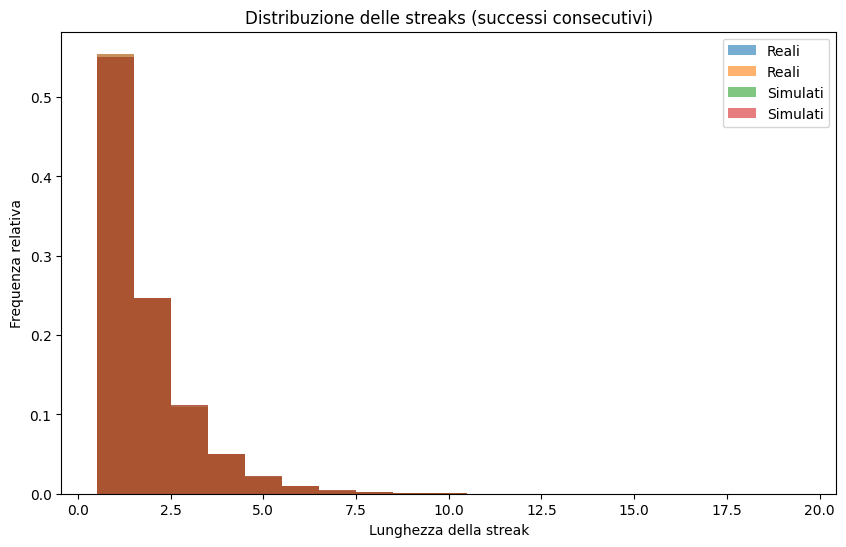

In [150]:
plt.figure(figsize=(10,6))
bins = np.arange(1, max(max(all_real_streaks), max(all_sim_streaks)) + 2) - 0.5  # binning corretto

plt.hist(all_real_streaks, bins=bins, alpha=0.6, label='Reali', density=True)
plt.hist(all_real_streaks, bins=bins, alpha=0.6, label='Reali', density=True)
plt.hist(all_sim_streaks, bins=bins, alpha=0.6, label='Simulati', density=True)
plt.hist(all_sim_streaks, bins=bins, alpha=0.6, label='Simulati', density=True)

plt.xlabel('Lunghezza della streak')
plt.ylabel('Frequenza relativa')
plt.title('Distribuzione delle streaks (successi consecutivi)')
plt.legend()
plt.show()

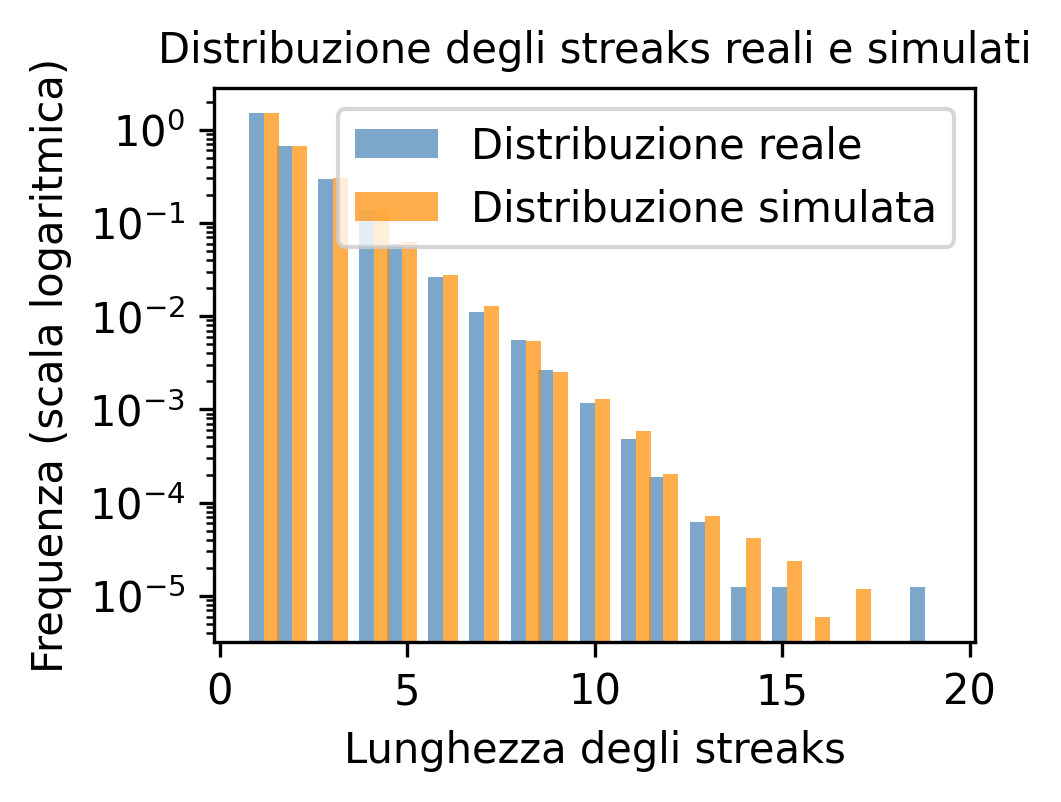

In [29]:
# Ottieni le frequenze per le sequenze reali e simulate
real_streaks_hist, bins_real = np.histogram(all_real_streaks, bins=50, density=True)
sim_streaks_hist, bins_sim = np.histogram(all_sim_streaks, bins=50, density=True)

# Troviamo il centro dei bin per il grafico
bin_centers_real = (bins_real[:-1] + bins_real[1:]) / 2
bin_centers_sim = (bins_sim[:-1] + bins_sim[1:]) / 2

# Se i bin delle sequenze reali e simulate sono diversi, allineamoli per avere lo stesso numero di bin
# Unificando i bin
bins = np.linspace(min(min(bins_real), min(bins_sim)), max(max(bins_real), max(bins_sim)), 50)

# Ricalcoliamo gli histogrammi con gli stessi bin
real_streaks_hist, _ = np.histogram(all_real_streaks, bins=bins, density=True)
sim_streaks_hist, _ = np.histogram(all_sim_streaks, bins=bins, density=True)

# Troviamo i centri dei bin per il grafico
bin_centers = (bins[:-1] + bins[1:]) / 2

# Plottiamo le distribuzioni in scala logaritmica sull'asse y
plt.figure(figsize=(3.27, 2.4), dpi=300)

# Plottiamo le distribuzioni come barre affiancate
width = 0.4  # Larghezza delle barre

# Distanziamo le barre delle distribuzioni reali e simulate
plt.bar(bin_centers - width/2, real_streaks_hist, width=width, label="Distribuzione reale", color="steelblue", alpha=0.7)
plt.bar(bin_centers + width/2, sim_streaks_hist, width=width, label="Distribuzione simulata", color="darkorange", alpha=0.7)

# Modifica l'asse y per avere una scala logaritmica
plt.yscale("log")

# Aggiungi etichette e titolo
plt.xlabel('Lunghezza degli streaks', fontsize=10)
plt.ylabel('Frequenza (scala logaritmica)', fontsize=10)
plt.title('Distribuzione degli streaks reali e simulati', fontsize=10)

# Aggiungi la legenda
plt.legend(fontsize=10)

# Mostra il grafico
plt.show()

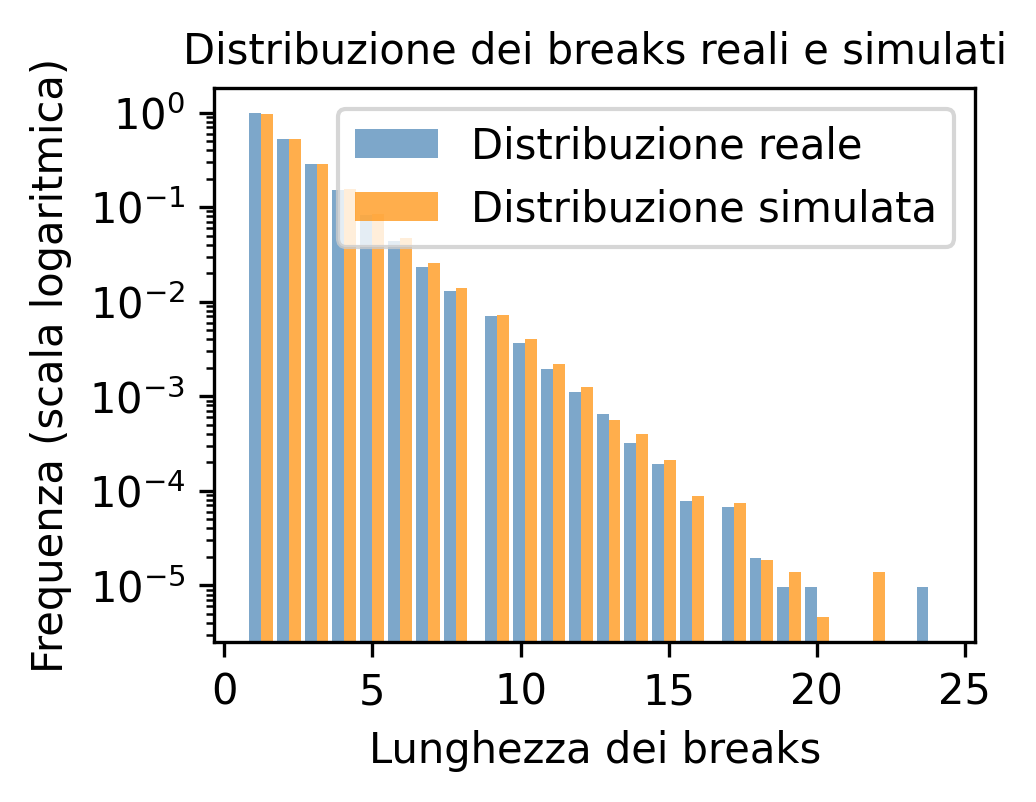

In [147]:
# Ottieni le frequenze per le sequenze reali e simulate
real_breaks_hist, bins_real = np.histogram(all_real_breaks, bins=50, density=True)
sim_breaks_hist, bins_sim = np.histogram(all_sim_breaks, bins=50, density=True)

# Troviamo il centro dei bin per il grafico
bin_centers_real = (bins_real[:-1] + bins_real[1:]) / 2
bin_centers_sim = (bins_sim[:-1] + bins_sim[1:]) / 2

# Se i bin delle sequenze reali e simulate sono diversi, allineamoli per avere lo stesso numero di bin
# Unificando i bin
bins = np.linspace(min(min(bins_real), min(bins_sim)), max(max(bins_real), max(bins_sim)), 50)

# Ricalcoliamo gli histogrammi con gli stessi bin
real_breaks_hist, _ = np.histogram(all_real_breaks, bins=bins, density=True)
sim_breaks_hist, _ = np.histogram(all_sim_breaks, bins=bins, density=True)

# Troviamo i centri dei bin per il grafico
bin_centers = (bins[:-1] + bins[1:]) / 2

# Plottiamo le distribuzioni in scala logaritmica sull'asse y
plt.figure(figsize=(3.27, 2.4), dpi=300)

# Plottiamo le distribuzioni come barre affiancate
width = 0.4  # Larghezza delle barre

# Distanziamo le barre delle distribuzioni reali e simulate
plt.bar(bin_centers - width/2, real_breaks_hist, width=width, label="Distribuzione reale", color="steelblue", alpha=0.7)
plt.bar(bin_centers + width/2, sim_breaks_hist, width=width, label="Distribuzione simulata", color="darkorange", alpha=0.7)

# Modifica l'asse y per avere una scala logaritmica
plt.yscale("log")

# Aggiungi etichette e titolo
plt.xlabel('Lunghezza dei breaks', fontsize=10)
plt.ylabel('Frequenza (scala logaritmica)', fontsize=10)
plt.title('Distribuzione dei breaks reali e simulati', fontsize=10)

# Aggiungi la legenda
plt.legend(fontsize=10)

# Mostra il grafico
plt.show()

Questo blocco di codice genera un grafico a istogramma che confronta la distribuzione delle lunghezze delle streaks (sequenze di successi consecutivi) tra i dati reali e i dati simulati. 

### Test statistici

Riepilogo delle alternative:\
Mann-Whitney U: Buono per confrontare due campioni indipendenti senza fare assunzioni sulla distribuzione dei dati.\
Anderson-Darling: Buono per confrontare le distribuzioni cumulative, sensibile alle code delle distribuzioni.\
Kolmogorov-Smirnov: Buono per confrontare le distribuzioni cumulative, ma sensibile alle differenze nelle code.\
Chi-quadrato: Buono per confrontare le frequenze osservate e attese, ma richiede frequenze attese positive.

In [30]:
ks_statistic, p_value = ks_2samp(all_real_streaks, all_sim_streaks)

print(f"Statistiche KS: {ks_statistic:.4f}")
print(f"P-value: {p_value}")

if p_value < 0.05:
    print("Le distribuzioni sono significativamente diverse.")
else:
    print("Non ci sono differenze significative tra le distribuzioni.")

Statistiche KS: 0.0049
P-value: 0.0018282497506739836
Le distribuzioni sono significativamente diverse.


Questo blocco di codice esegue un test di Kolmogorov-Smirnov (KS) per confrontare la distribuzione delle lunghezze delle streaks reali e simulate.

Il test di Kolmogorov-Smirnov (KS) è un test statistico non parametrico utilizzato per confrontare due distribuzioni di probabilità e verificare se provengono dalla stessa distribuzione. È ampiamente utilizzato per confrontare una distribuzione empirica con una distribuzione teorica, ma può anche essere applicato per confrontare due distribuzioni empiriche.

In [31]:
# Calcola gli istogrammi delle streaks reali e simulate
bins = np.arange(1, max(max(all_real_streaks), max(all_sim_streaks)) + 2)  # Bin comuni per entrambi i set di dati
cont_real, _ = np.histogram(all_real_streaks, bins=bins)
cont_sim, _ = np.histogram(all_sim_streaks, bins=bins)

# Aggiungi 0.5 per evitare conteggi nulli (correzione di continuità)
cont_real = cont_real + 0.5
cont_sim = cont_sim + 0.5

# Crea una matrice 2D con le distribuzioni delle streaks reali e simulate
data = np.array([cont_real, cont_sim])

# Esegui il test del chi-quadrato
chi2_stat, p_val, dof, expected = chi2_contingency(data)

# Stampa i risultati
print(f"Chi-quadrato: {chi2_stat:.4f}")
print(f"P-value: {p_val}")

# Interpreta il p-value
if p_val < 0.05:
    print("Le distribuzioni sono significativamente diverse.")
else:
    print("Non ci sono differenze significative tra le distribuzioni.")

Chi-quadrato: 42.7837
P-value: 0.0008584982241811616
Le distribuzioni sono significativamente diverse.


In [32]:
stat, p_value = mannwhitneyu(all_real_streaks, all_sim_streaks, alternative='two-sided')

print(f"Statistiche Mann-Whitney U: {stat:.4f}")
print(f"P-value: {p_value}")

if p_value < 0.05:
    print("Le distribuzioni sono significativamente diverse.")
else:
    print("Non ci sono differenze significative tra le distribuzioni.")

Statistiche Mann-Whitney U: 50018788805.0000
P-value: 1.9021521924671362e-05
Le distribuzioni sono significativamente diverse.


Il codice che hai fornito esegue un test di Mann-Whitney U (noto anche come test di Wilcoxon-Mann-Whitney), che è un test statistico non parametrico utilizzato per determinare se due campioni indipendenti provengono dalla stessa distribuzione.

Il test di Mann-Whitney U è un test statistico non parametrico utilizzato per confrontare due gruppi indipendenti per determinare se provengono dalla stessa distribuzione. È particolarmente utile quando i dati non seguono una distribuzione normale. La sua forza sta nel fatto che non fa assunzioni riguardo alla forma della distribuzione dei dati, a differenza dei test parametrici come il test t di Student.

In [33]:
stat, crit_vals, sig_level = anderson_ksamp([all_real_streaks, all_sim_streaks])

print(f"Statistiche Anderson-Darling: {stat:.4f}")
print(f"Valori critici: {crit_vals}")
print(f"Livello di significatività: {sig_level}")

if stat > crit_vals[2]:
    print("Le distribuzioni sono significativamente diverse.")
else:
    print("Non ci sono differenze significative tra le distribuzioni.")

Statistiche Anderson-Darling: 18.1668
Valori critici: [0.325 1.226 1.961 2.718 3.752 4.592 6.546]
Livello di significatività: 0.001
Le distribuzioni sono significativamente diverse.


C:\Users\franc\AppData\Local\Temp\ipykernel_13760\3400450282.py:1: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  stat, crit_vals, sig_level = anderson_ksamp([all_real_streaks, all_sim_streaks])


Il codice che hai condiviso utilizza il test di Anderson-Darling per il confronto di più campioni (anderson_ksamp), che è una variante del test di Kolmogorov-Smirnov (KS) progettata per confrontare più di due campioni. In particolare, il test di Anderson-Darling si applica a due o più campioni indipendenti, con lo scopo di testare se provengono dalla stessa distribuzione.

In [34]:
real_streaks, real_breaks = estrai_streaks_breaks(all_real_streaks)
sim_streaks, sim_breaks = estrai_streaks_breaks(all_sim_streaks)

Le due righe di codice che hai condiviso chiamano la funzione estrai_streaks_breaks sui dati all_real_streaks e all_sim_streaks, separando le sequenze di streaks (sequenze di successi consecutivi) e breaks (interruzioni, ovvero fallimenti consecutivi) per entrambi i set di dati.

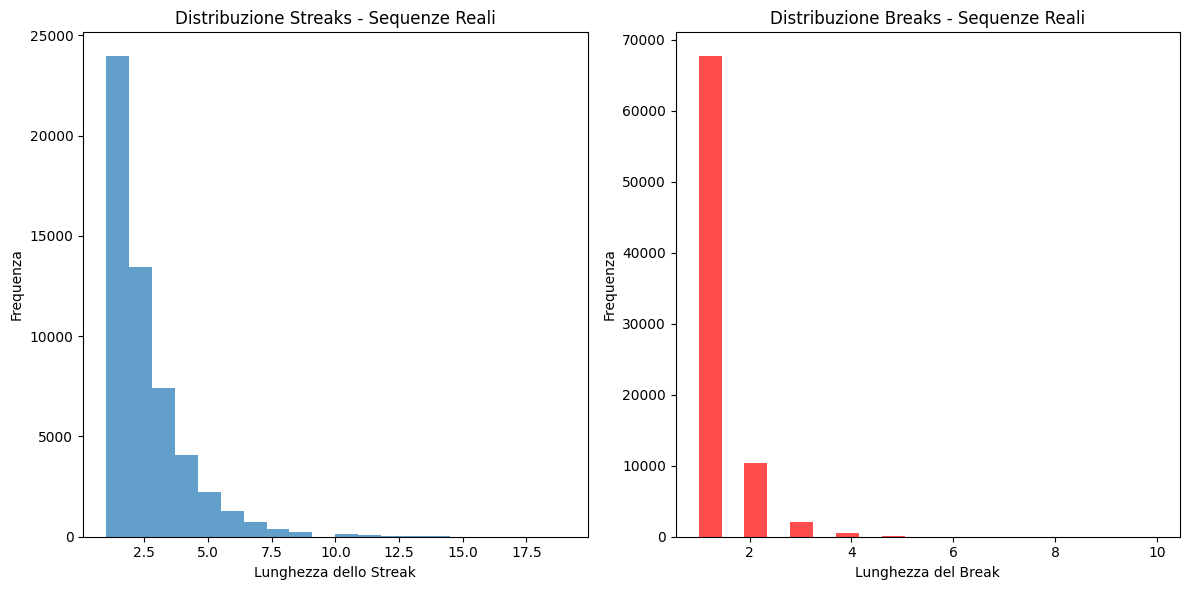

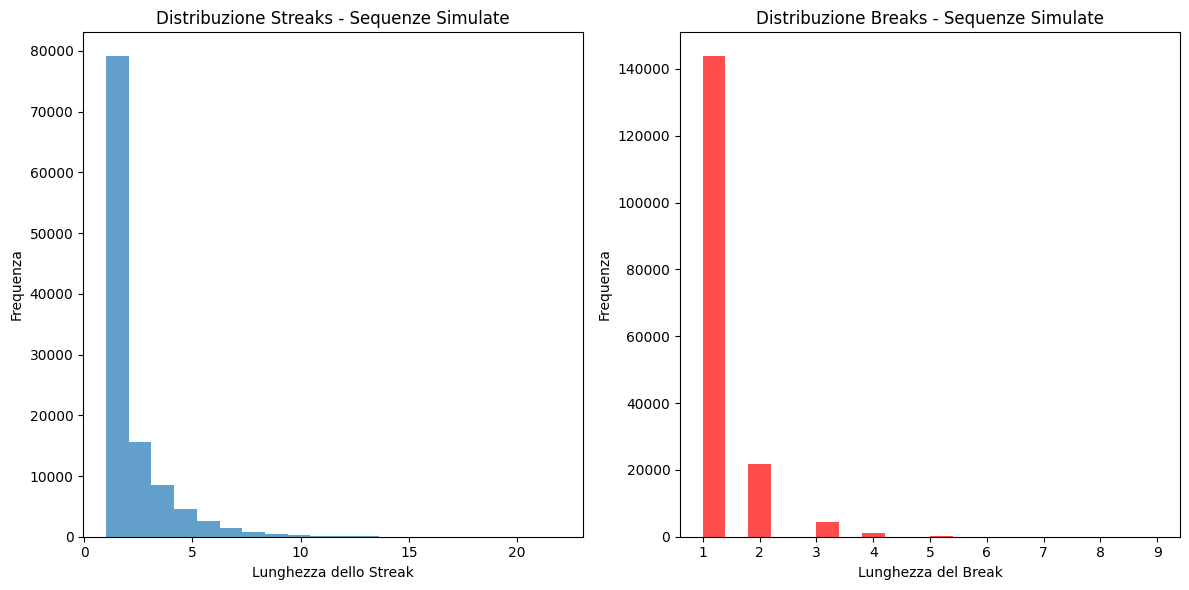

In [35]:
def plot_distribution(streaks, breaks, title):
    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 2, 1)
    plt.hist(streaks, bins=20, alpha=0.7, label="Streaks")
    plt.title(f"Distribuzione Streaks - {title}")
    plt.xlabel("Lunghezza dello Streak")
    plt.ylabel("Frequenza")
    
    plt.subplot(1, 2, 2)
    plt.hist(breaks, bins=20, alpha=0.7, label="Breaks", color="red")
    plt.title(f"Distribuzione Breaks - {title}")
    plt.xlabel("Lunghezza del Break")
    plt.ylabel("Frequenza")
    
    plt.tight_layout()
    plt.show()

plot_distribution(real_streaks, real_breaks, "Sequenze Reali")
plot_distribution(sim_streaks, sim_breaks, "Sequenze Simulate")

La funzione plot_distribution che hai fornito serve per visualizzare le distribuzioni delle sequenze di streaks (successi consecutivi) e breaks (fallimenti consecutivi) in un formato grafico a due sotto-grafici affiancati (subplots).

## Correlazioni

Conclusione e Interpretazione:\
Autocorrelazione: Se c'è un pattern significativo di autocorrelazione, significa che i successi/insuccessi sono correlati nel tempo. Potresti vedere picchi nei grafici dell'autocorrelazione.\
Correlazione di Spearman: Se la correlazione è significativa (con un p-value inferiore a 0.05), significa che le due sequenze (reale e simulata) sono correlate monotonicamente.\
Test di Granger: Se il test di Granger indica causalità, allora una sequenza potrebbe predire l'altra.

### Autocorrelazione

In [153]:
lag = 1
autocorrs_reali = [autocorrelazione_lag(seq, lag) for seq in seq]
autocorrs_bern = [autocorrelazione_lag(seq, lag) for seq in sim_seq]

media_reale = np.nanmean(autocorrs_reali)
media_bern = np.nanmean(autocorrs_bern)

print(f"Autocorrelazione media reale (lag {lag}): {media_reale:.4f}")
print(f"Autocorrelazione media Bernoulli (lag {lag}): {media_bern:.4f}")

Autocorrelazione media reale (lag 1): -0.0183
Autocorrelazione media Bernoulli (lag 1): -0.0058


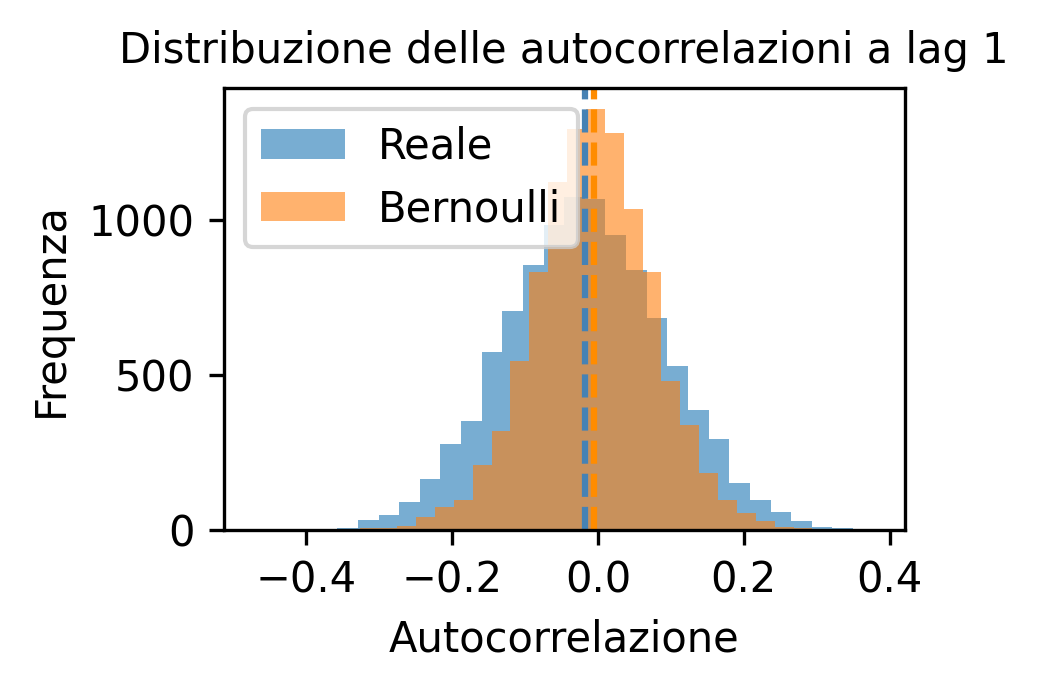

In [156]:
plt.figure(figsize=(3.27, 2.4), dpi=300)
plt.hist(autocorrs_reali, bins=30, alpha=0.6, label='Reale')
plt.hist(autocorrs_bern, bins=30, alpha=0.6, label='Bernoulli')
plt.axvline(media_reale, color='steelblue', linestyle='--')
plt.axvline(media_bern, color='darkorange', linestyle='--')
plt.legend(fontsize=10)
plt.title(f"Distribuzione delle autocorrelazioni a lag {lag}", fontsize=10)
plt.xlabel("Autocorrelazione", fontsize=10)
plt.ylabel("Frequenza", fontsize=10)
plt.tight_layout()
plt.show()

In [158]:
stat, p = mannwhitneyu(autocorrs_reali, autocorrs_bern, alternative='two-sided')
print(f"p-value test U di Mann–Whitney: {p}")

p-value test U di Mann–Whitney: 1.5413154017930583e-21


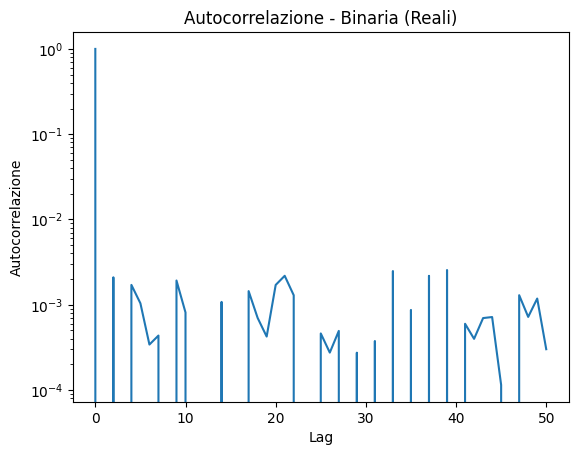

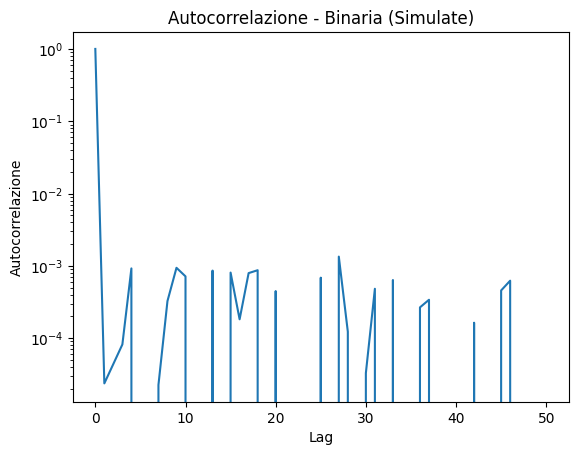

In [36]:
def plot_binary_autocorr(sequences, title="Autocorrelazione"):
    seq_concat = np.concatenate(sequences)  # concatena le varie sequenze binarie
    acf_vals = acf(seq_concat, nlags=50)
    plt.plot(acf_vals)
    plt.title(title)
    plt.xlabel("Lag")
    plt.ylabel("Autocorrelazione")
    plt.yscale("log")
    plt.show()

plot_binary_autocorr(seq, "Autocorrelazione - Binaria (Reali)")
plot_binary_autocorr(sim_seq, "Autocorrelazione - Binaria (Simulate)")

La funzione plot_autocorrelation calcola e traccia l'autocorrelazione di una sequenza di dati, quindi mostra la relazione tra una sequenza e le sue versioni ritardate (lag). L'autocorrelazione misura la somiglianza tra una serie temporale e se stessa a intervalli di tempo (lag) differenti.

### Correlazione di Spearman

In [37]:
min_length = min(len(all_real_streaks), len(all_sim_streaks))

real_streaks_aligned = all_real_streaks[:min_length]
sim_streaks_aligned = all_sim_streaks[:min_length]

from scipy.stats import spearmanr

correlation, p_value = spearmanr(real_streaks_aligned, sim_streaks_aligned)

print(f"Correlazione di Spearman: {correlation:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("C'è una correlazione significativa tra le sequenze.")
else:
    print("Non c'è correlazione significativa tra le sequenze.")

Correlazione di Spearman: 0.0005
P-value: 0.8040
Non c'è correlazione significativa tra le sequenze.


###  Correlazione di Granger

#### Allineando le lunghezze

In [38]:
min_length = min(len(all_real_streaks), len(all_sim_streaks))

real_streaks_aligned = all_real_streaks[:min_length]
sim_streaks_aligned = all_sim_streaks[:min_length]

data = pd.DataFrame({'real': real_streaks_aligned, 'sim': sim_streaks_aligned})

from statsmodels.tsa.stattools import grangercausalitytests

max_lag = 10  # Numero massimo di lag da testare
gc_test = grangercausalitytests(data, max_lag, verbose=True)

C:\Users\franc\anaconda3\envs\myenv\Lib\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(



Granger Causality
number of lags (no zero) 1
ssr based F test:         F=0.0628  , p=0.8022  , df_denom=219330, df_num=1
ssr based chi2 test:   chi2=0.0628  , p=0.8022  , df=1
likelihood ratio test: chi2=0.0628  , p=0.8022  , df=1
parameter F test:         F=0.0628  , p=0.8022  , df_denom=219330, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=2.4337  , p=0.0877  , df_denom=219327, df_num=2
ssr based chi2 test:   chi2=4.8676  , p=0.0877  , df=2
likelihood ratio test: chi2=4.8675  , p=0.0877  , df=2
parameter F test:         F=2.4337  , p=0.0877  , df_denom=219327, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=2.2562  , p=0.0797  , df_denom=219324, df_num=3
ssr based chi2 test:   chi2=6.7688  , p=0.0796  , df=3
likelihood ratio test: chi2=6.7687  , p=0.0796  , df=3
parameter F test:         F=2.2562  , p=0.0797  , df_denom=219324, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F test:         F=1.

#### Campionamento casuale

In [39]:
min_length = min(len(all_real_streaks), len(all_sim_streaks))

np.random.seed(42)
sampled_real_streaks = np.random.choice(all_real_streaks, size=min_length, replace=False)
sampled_sim_streaks = np.random.choice(all_sim_streaks, size=min_length, replace=False)

data = pd.DataFrame({'real': sampled_real_streaks, 'sim': sampled_sim_streaks})

from statsmodels.tsa.stattools import grangercausalitytests

max_lag = 10  # Numero massimo di lag da testare
gc_test = grangercausalitytests(data, max_lag, verbose=True)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=3.8978  , p=0.0484  , df_denom=219330, df_num=1
ssr based chi2 test:   chi2=3.8978  , p=0.0483  , df=1
likelihood ratio test: chi2=3.8978  , p=0.0483  , df=1
parameter F test:         F=3.8978  , p=0.0484  , df_denom=219330, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=2.5489  , p=0.0782  , df_denom=219327, df_num=2
ssr based chi2 test:   chi2=5.0979  , p=0.0782  , df=2
likelihood ratio test: chi2=5.0978  , p=0.0782  , df=2
parameter F test:         F=2.5489  , p=0.0782  , df_denom=219327, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=1.7067  , p=0.1632  , df_denom=219324, df_num=3
ssr based chi2 test:   chi2=5.1203  , p=0.1632  , df=3
likelihood ratio test: chi2=5.1202  , p=0.1632  , df=3
parameter F test:         F=1.7067  , p=0.1632  , df_denom=219324, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F test:         F=1.

#### Interpolazione sequenze

In [40]:
target_length = min(len(all_real_streaks), len(all_sim_streaks))

real_interpolated = interpolate_sequence(all_real_streaks, target_length)
sim_interpolated = interpolate_sequence(all_sim_streaks, target_length)

data = pd.DataFrame({'real': real_interpolated, 'sim': sim_interpolated})

from statsmodels.tsa.stattools import grangercausalitytests

max_lag = 10  # Numero massimo di lag da testare
gc_test = grangercausalitytests(data, max_lag, verbose=True)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=0.8223  , p=0.3645  , df_denom=219330, df_num=1
ssr based chi2 test:   chi2=0.8223  , p=0.3645  , df=1
likelihood ratio test: chi2=0.8223  , p=0.3645  , df=1
parameter F test:         F=0.8223  , p=0.3645  , df_denom=219330, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=0.4158  , p=0.6598  , df_denom=219327, df_num=2
ssr based chi2 test:   chi2=0.8316  , p=0.6598  , df=2
likelihood ratio test: chi2=0.8316  , p=0.6598  , df=2
parameter F test:         F=0.4158  , p=0.6598  , df_denom=219327, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=0.2767  , p=0.8422  , df_denom=219324, df_num=3
ssr based chi2 test:   chi2=0.8302  , p=0.8422  , df=3
likelihood ratio test: chi2=0.8302  , p=0.8422  , df=3
parameter F test:         F=0.2767  , p=0.8422  , df_denom=219324, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F test:         F=0.

In [45]:
seq_totale = list(chain.from_iterable(seq))
ljung_result = acorr_ljungbox(seq_totale, lags=20)

In [46]:
for i, s in enumerate(seq):
    if len(s) > 20:  # serve una sequenza abbastanza lunga
        res = acorr_ljungbox(s, lags=20)

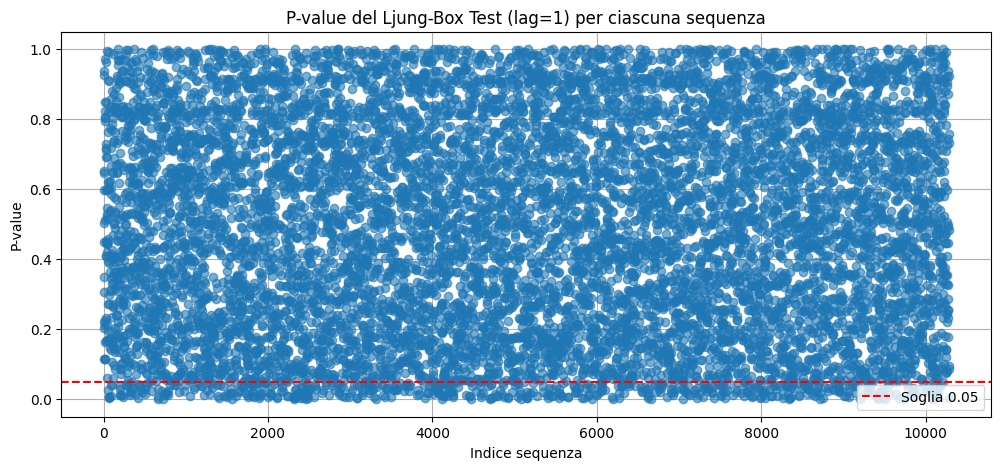

In [47]:
p_values = []

# Calcolo p-value al primo lag per ogni sequenza
for seq in seq:
    if len(seq) > 20:
        res = acorr_ljungbox(seq, lags=1)
        p = res['lb_pvalue'].iloc[0]
        p_values.append(p)

# Plot
plt.figure(figsize=(12, 5))
plt.plot(p_values, marker='o', linestyle='none', alpha=0.6)
plt.axhline(0.05, color='red', linestyle='--', label='Soglia 0.05')
plt.title("P-value del Ljung-Box Test (lag=1) per ciascuna sequenza")
plt.xlabel("Indice sequenza")
plt.ylabel("P-value")
plt.legend()
plt.grid(True)
plt.show()

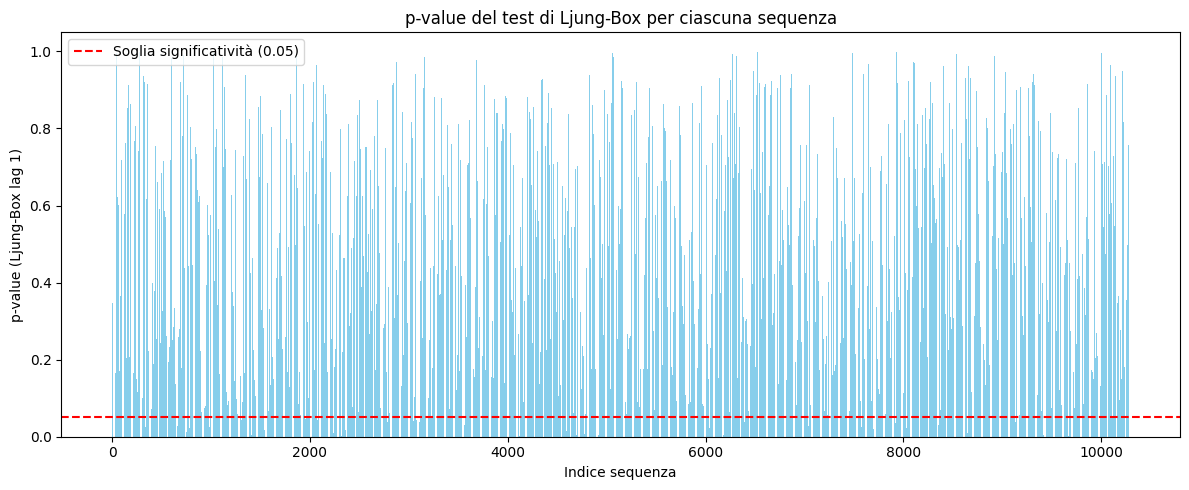

In [53]:
p_values = []
indice_seq = []

for i, s in enumerate(seq):  # o `seq_simulate` se vuoi testare le simulate
    if len(s) > 20:  # Il test richiede una lunghezza minima
        try:
            res = acorr_ljungbox(s, lags=[1], return_df=True)
            p = res['lb_pvalue'].iloc[0]
            p_values.append(p)
            indice_seq.append(i)
        except Exception as e:
            print(f"Errore con la sequenza {i}: {e}")

# Plot
plt.figure(figsize=(12, 5))
plt.bar(indice_seq, p_values, color='skyblue')
plt.axhline(0.05, color='red', linestyle='--', label='Soglia significatività (0.05)')
plt.xlabel("Indice sequenza")
plt.ylabel("p-value (Ljung-Box lag 1)")
plt.title("p-value del test di Ljung-Box per ciascuna sequenza")
plt.legend()
plt.tight_layout()
plt.show()

## Sim con markov chain

In [54]:
def calcola_transizioni(s):
    # Inizializza i conteggi delle transizioni
    p00_count = 0  # Transizione da 0 a 0
    p11_count = 0  # Transizione da 1 a 1
    p01_count = 0  # Transizione da 0 a 1
    p10_count = 0  # Transizione da 1 a 0

    # Itera sulla sequenza e conta le transizioni
    for i in range(1, len(s)):
        if s[i-1] == 0 and s[i] == 0:
            p00_count += 1
        elif s[i-1] == 1 and s[i] == 1:
            p11_count += 1
        elif s[i-1] == 0 and s[i] == 1:
            p01_count += 1
        elif s[i-1] == 1 and s[i] == 0:
            p10_count += 1

    # Calcola le probabilità di transizione
    total_transitions = p00_count + p11_count + p01_count + p10_count
    p00 = p00_count / total_transitions if total_transitions > 0 else 0
    p11 = p11_count / total_transitions if total_transitions > 0 else 0
    p01 = p01_count / total_transitions if total_transitions > 0 else 0
    p10 = p10_count / total_transitions if total_transitions > 0 else 0

    return p00, p11, p01, p10

In [55]:
total_p00 = total_p11 = total_p01 = total_p10 = 0
num_sequenze = len(seq)

In [56]:
for s in seq:
    p00, p11, p01, p10 = calcola_transizioni(s)
    total_p00 += p00
    total_p11 += p11
    total_p01 += p01
    total_p10 += p10

In [57]:
p00_avg = total_p00 / num_sequenze
p11_avg = total_p11 / num_sequenze
p01_avg = total_p01 / num_sequenze
p10_avg = total_p10 / num_sequenze

In [58]:
print(f"Probabilità media di transizione (su {num_sequenze} sequenze):")
print(f"p00 (da 0 a 0): {p00_avg:.2f}")
print(f"p11 (da 1 a 1): {p11_avg:.2f}")
print(f"p01 (da 0 a 1): {p01_avg:.2f}")
print(f"p10 (da 1 a 0): {p10_avg:.2f}")

Probabilità media di transizione (su 10284 sequenze):
p00 (da 0 a 0): 0.30
p11 (da 1 a 1): 0.21
p01 (da 0 a 1): 0.25
p10 (da 1 a 0): 0.25


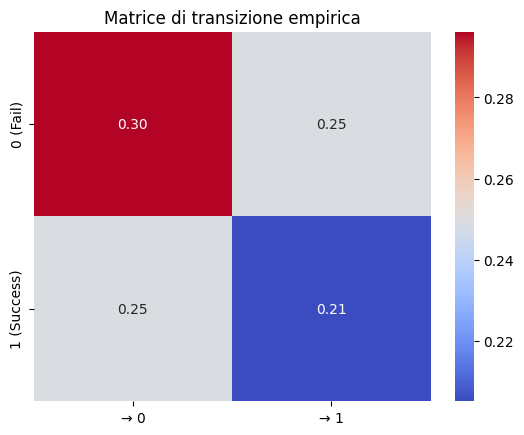

In [59]:
matrix = pd.DataFrame([[p00_avg, p01_avg], [p10_avg, p11_avg]], index=["0 (Fail)", "1 (Success)"], columns=["→ 0", "→ 1"])

sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice di transizione empirica")
plt.show()

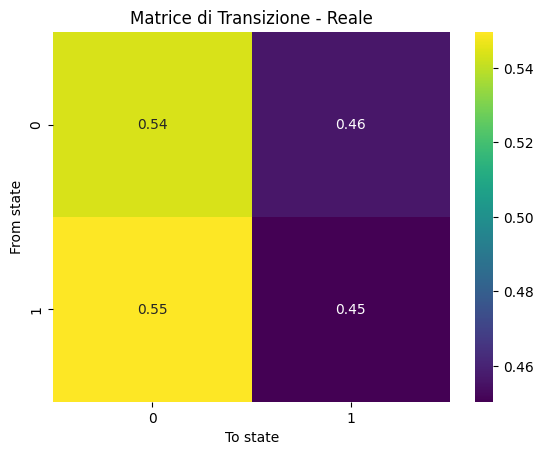

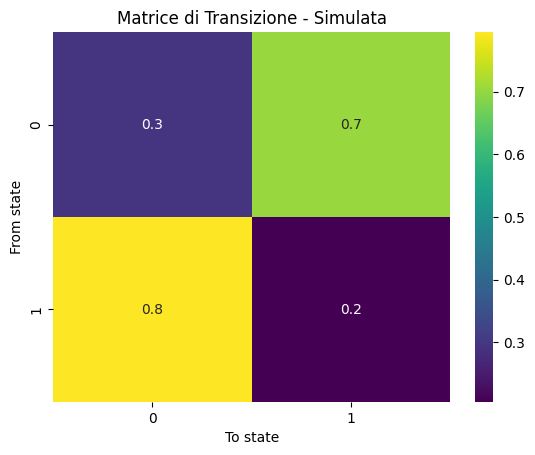

In [63]:
def calcola_matrice_transizione(sequences):
    trans_counts = np.zeros((2, 2))
    for seq in sequences:
        for i in range(len(seq) - 1):
            from_state = seq[i]
            to_state = seq[i+1]
            trans_counts[from_state][to_state] += 1

    # Evita divisione per zero
    row_sums = trans_counts.sum(axis=1, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        trans_probs = np.nan_to_num(trans_counts / row_sums)
    
    return trans_probs

# Calcolo per sequenze reali e simulate
trans_real = calcola_matrice_transizione(seq)
trans_sim = calcola_matrice_transizione(sim_seq_m)

# Heatmap
def plot_transition_matrix(matrix, title):
    sns.heatmap(matrix, annot=True, cmap="viridis", xticklabels=[0, 1], yticklabels=[0, 1])
    plt.xlabel("To state")
    plt.ylabel("From state")
    plt.title(title)
    plt.show()

plot_transition_matrix(trans_real, "Matrice di Transizione - Reale")
plot_transition_matrix(trans_sim, "Matrice di Transizione - Simulata")


In [61]:
sim_seq_m = []
for i in range(len(seq)):
    lunghezza_random = random.randint(lunghezza_min, lunghezza_max)
    sim = simula_markov(p00_avg, p11_avg, lunghezza_random)
    sim_seq_m.append(sim)

In [62]:
all_sim_m_streaks = []
for s in sim_seq_m:
    streaks = distribuzione_streaks(s, valore=1)
    all_sim_m_streaks.extend(streaks)

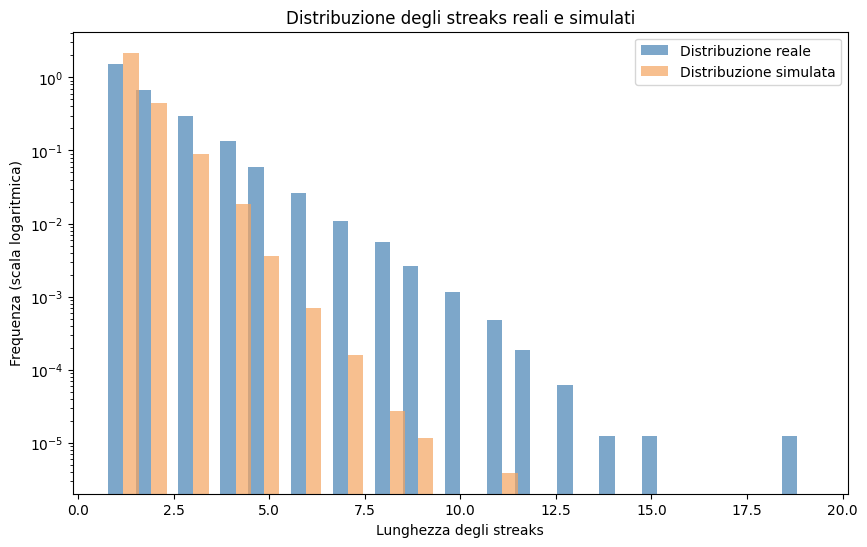

In [64]:
# Ottieni le frequenze per le sequenze reali e simulate
real_streaks_hist, bins_real = np.histogram(all_real_streaks, bins=50, density=True)
sim_streaks_hist, bins_sim = np.histogram(all_sim_m_streaks, bins=50, density=True)

# Troviamo il centro dei bin per il grafico
bin_centers_real = (bins_real[:-1] + bins_real[1:]) / 2
bin_centers_sim = (bins_sim[:-1] + bins_sim[1:]) / 2

# Se i bin delle sequenze reali e simulate sono diversi, allineamoli per avere lo stesso numero di bin
# Unificando i bin
bins = np.linspace(min(min(bins_real), min(bins_sim)), max(max(bins_real), max(bins_sim)), 50)

# Ricalcoliamo gli histogrammi con gli stessi bin
real_streaks_hist, _ = np.histogram(all_real_streaks, bins=bins, density=True)
sim_streaks_hist, _ = np.histogram(all_sim_m_streaks, bins=bins, density=True)

# Troviamo i centri dei bin per il grafico
bin_centers = (bins[:-1] + bins[1:]) / 2

# Plottiamo le distribuzioni in scala logaritmica sull'asse y
plt.figure(figsize=(10, 6))

# Plottiamo le distribuzioni come barre affiancate
width = 0.4  # Larghezza delle barre

# Distanziamo le barre delle distribuzioni reali e simulate
plt.bar(bin_centers - width/2, real_streaks_hist, width=width, label="Distribuzione reale", color="steelblue", alpha=0.7)
plt.bar(bin_centers + width/2, sim_streaks_hist, width=width, label="Distribuzione simulata", color="sandybrown", alpha=0.7)

# Modifica l'asse y per avere una scala logaritmica
plt.yscale("log")

# Aggiungi etichette e titolo
plt.xlabel('Lunghezza degli streaks')
plt.ylabel('Frequenza (scala logaritmica)')
plt.title('Distribuzione degli streaks reali e simulati')

# Aggiungi la legenda
plt.legend()

# Mostra il grafico
plt.show()

In [65]:
stat, p_value = shapiro(all_real_streaks)
print("Shapiro-Wilk test per le sequenze reali:", stat, p_value)

# Test di normalità per le sequenze simulate
stat, p_value = shapiro(all_sim_m_streaks)
print("Shapiro-Wilk test per le sequenze simulate:", stat, p_value)

Shapiro-Wilk test per le sequenze reali: 0.6954630833795465 5.7459526628600946e-164
Shapiro-Wilk test per le sequenze simulate: 0.5036645423071919 4.920458949932686e-205


C:\Users\franc\anaconda3\envs\myenv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 219334.
  res = hypotest_fun_out(*samples, **kwds)
C:\Users\franc\anaconda3\envs\myenv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:586: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 692227.
  res = hypotest_fun_out(*samples, **kwds)


In [66]:
ks_stat, ks_p_value = ks_2samp(all_real_streaks, all_sim_m_streaks)
print(f"KS test: statistica = {ks_stat}, p-value = {ks_p_value}")

KS test: statistica = 0.24131807308432485, p-value = 0.0


In [67]:
stat, p_value = mannwhitneyu(all_real_streaks, all_sim_m_streaks)
print(f"Mann-Whitney test: statistica = {stat}, p-value = {p_value}")

Mann-Whitney test: statistica = 96071098061.0, p-value = 0.0


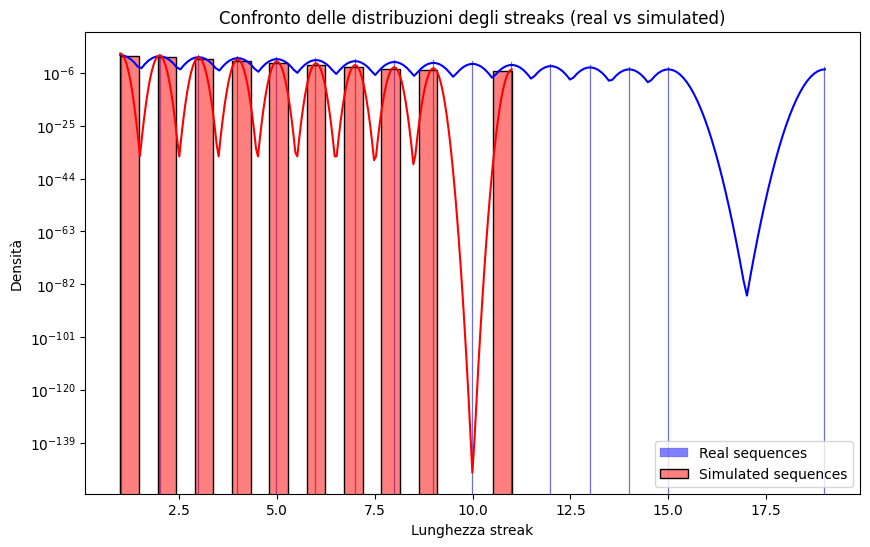

In [68]:
plt.figure(figsize=(10, 6))

# Traccia le distribuzioni
sns.histplot(all_real_streaks, kde=True, color='blue', label='Real sequences', stat='density')
sns.histplot(all_sim_m_streaks, kde=True, color='red', label='Simulated sequences', stat='density')

plt.title('Confronto delle distribuzioni degli streaks (real vs simulated)')
plt.xlabel('Lunghezza streak')
plt.ylabel('Densità')
plt.yscale("log")
plt.legend()
plt.show()

## Peso partite

In [69]:
# Supponiamo che "sq" sia la squadra che ha fatto l'azione
# e "success" è se l'azione è riuscita (1 o 0)
# "game_id" è il codice partita

partite = []

for game_id_val in df["game_id"].unique():
    game = df[df["game_id"] == game_id_val]

    # Le due squadre che giocano
    teams = game["player1_team_abbreviation"].unique()
    if len(teams) != 2:
        continue  # scartiamo partite strane

    team1, team2 = teams

    for idx, row in game.iterrows():
        squadra_azione = row["player1_team_abbreviation"]
        risultato = row["success"]

        if squadra_azione == team1:
            team_A = team1
            team_B = team2
        else:
            team_A = team2
            team_B = team1

        partite.append([team_A, team_B, risultato])

# Ora partite è una lista di [team_A, team_B, risultato]
partite = pd.DataFrame(partite, columns=["team_A", "team_B", "result"])

In [70]:
# Raggruppa per partita: sommiamo i successi e contiamo le azioni
agg_partite = partite.groupby(["team_A", "team_B"]).agg(
    successi=("result", "sum"),
    totali=("result", "count")
).reset_index()

In [71]:
squadre = np.unique(agg_partite[["team_A", "team_B"]].values.flatten())

In [72]:
n_squadre = len(squadre)

In [73]:
squadra_to_idx = {squadra: idx for idx, squadra in enumerate(squadre)}

In [74]:
p_init = np.full(n_squadre, 0.5)
bounds = [(0.01, 0.99) for _ in range(n_squadre)]

In [75]:
result = minimize(
    log_likelihood_globale,
    p_init,
    args=(agg_partite, squadra_to_idx),
    bounds=bounds,
    method="L-BFGS-B",
    options={'disp': True, 'maxiter': 1000}
)

In [76]:
p_stimati = result.x
p_squadre = {squadra: p_stimati[idx] for squadra, idx in squadra_to_idx.items()}

In [77]:
squadre_ordinate = sorted(p_squadre.items(), key=lambda x: x[1], reverse=True)
squadre_lista = [s[0] for s in squadre_ordinate]
p_lista = [s[1] for s in squadre_ordinate]

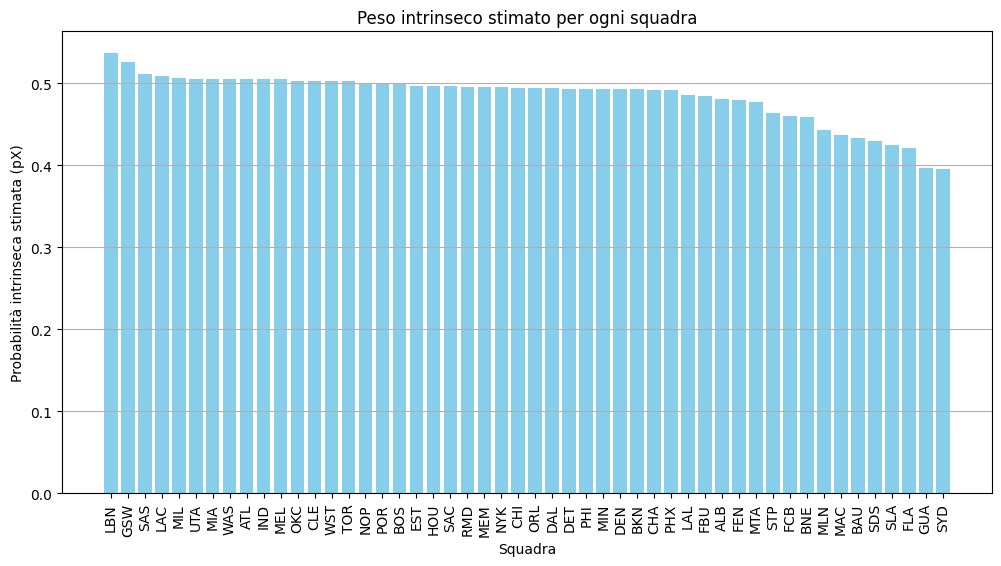

In [78]:
plt.figure(figsize=(12, 6))
plt.bar(squadre_lista, p_lista, color="skyblue")
plt.xticks(rotation=90)
plt.xlabel("Squadra")
plt.ylabel("Probabilità intrinseca stimata (pX)")
plt.title("Peso intrinseco stimato per ogni squadra")
plt.grid(axis='y')
plt.show()

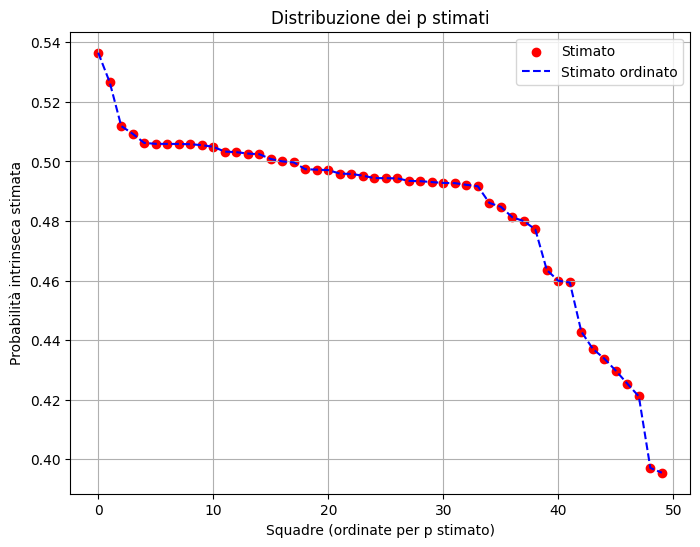

In [79]:
plt.figure(figsize=(8, 6))
plt.scatter(range(len(p_lista)), p_lista, color="red", label="Stimato")
plt.plot(sorted(p_lista, reverse=True), linestyle='--', color='blue', label="Stimato ordinato")

plt.xlabel("Squadre (ordinate per p stimato)")
plt.ylabel("Probabilità intrinseca stimata")
plt.title("Distribuzione dei p stimati")
plt.legend()
plt.grid(True)
plt.show()

In [80]:
n = len(squadre_lista)
mat_vittorie = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if i != j:
            pA = p_squadre[squadre_lista[i]]
            pB = p_squadre[squadre_lista[j]]
            mat_vittorie[i, j] = pA * (1 - pB)
        else:
            mat_vittorie[i, j] = np.nan

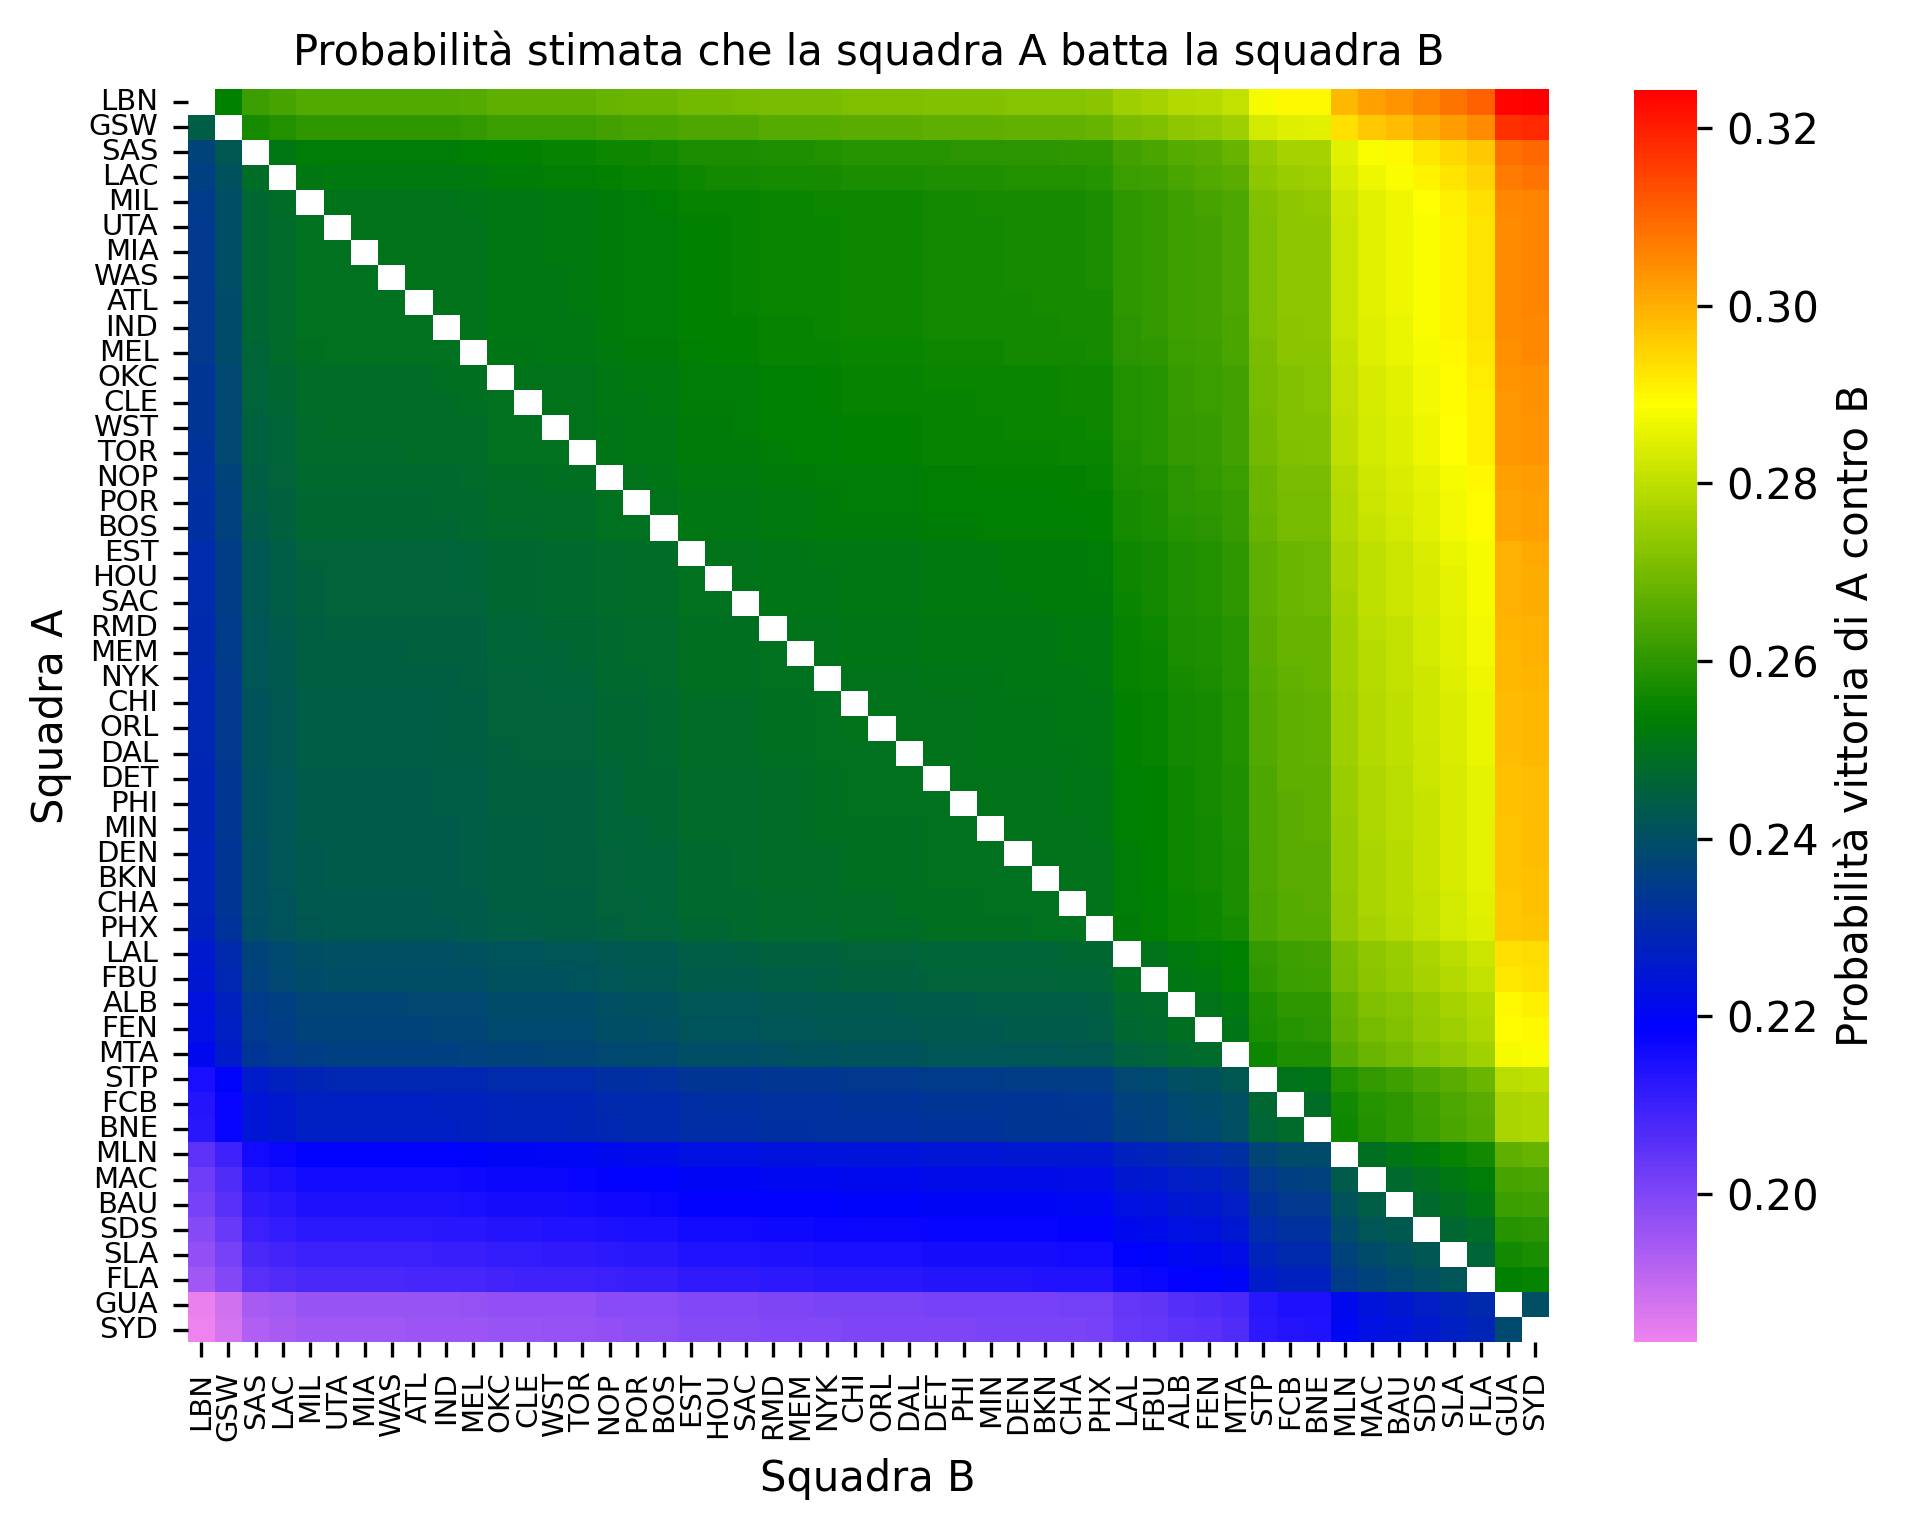

In [81]:
min_prob = np.nanmin(mat_vittorie)
max_prob = np.nanmax(mat_vittorie)

# Definisci il colormap personalizzato (dal viola al rosso, passando per l'arcobaleno)
cmap = LinearSegmentedColormap.from_list("custom_cmap", ["violet", "blue", "green", "yellow", "red"])

# Crea la heatmap con il colormap personalizzato
plt.figure(figsize=(6.54, 5.2), dpi=300)
sns.heatmap(
    mat_vittorie,
    xticklabels=squadre_lista,
    yticklabels=squadre_lista,
    cmap=cmap,  # Usa il colormap personalizzato
    vmin=min_prob, vmax=max_prob,  # Impostiamo il range della palette
    annot=False,  # Se vuoi vedere i numeri, imposta a True
    fmt=".2f",  # Formato numerico
    cbar_kws={"label": "Probabilità vittoria di A contro B"}  # Etichetta della barra dei colori
)

# Imposta il titolo e la disposizione degli assi
plt.xlabel("Squadra B", fontsize=10)
plt.ylabel("Squadra A", fontsize=10)
plt.title("Probabilità stimata che la squadra A batta la squadra B", fontsize=10)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

# Ottimizza il layout e mostra la heatmap
plt.tight_layout()
plt.show()

## Previsioni

In [82]:
df['prob_vittoria_A'] = df.apply(calcola_probabilita, axis=1)
dft['prob_vittoria_A'] = dft.apply(calcola_probabilita, axis=1)

In [83]:
def estrai_punteggio(row):
    # Verifica se il punteggio è una stringa e contiene un formato del tipo "X - Y"
    if isinstance(row['score'], str) and ' - ' in row['score']:
        punteggi = row['score'].split(' - ')
        return int(punteggi[0]), int(punteggi[1])
    else:
        # In caso di errore o formato non valido, ritorna valori nulli o zero
        return np.nan, np.nan

In [84]:
df[['punteggio_A', 'punteggio_B']] = df.apply(estrai_punteggio, axis=1, result_type="expand")
dft[['punteggio_A', 'punteggio_B']] = dft.apply(estrai_punteggio, axis=1, result_type="expand")

In [85]:
# Gestisci eventuali valori NaN (se ci sono righe con dati incompleti)
df = df.dropna(subset=['punteggio_A', 'punteggio_B'])
dft = dft.dropna(subset=['punteggio_A', 'punteggio_B'])

In [86]:
df['vittoria_A'] = (df['punteggio_A'] > df['punteggio_B']).astype(int)

In [87]:
# 4. Modello predittivo per predire l'andamento delle partite (regressione logistica o altro)
# Costruiremo un modello di regressione logistica per predire il risultato delle partite

X = df[['prob_vittoria_A']]  # Features (in questo caso la probabilità calcolata)
y = df['vittoria_A']  # Target: 1 se squadra A vince, 0 se perde

In [88]:
# Divisione in training e test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [89]:
# Modello di regressione logistica
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [90]:
# 5. Fare previsioni sulla stagione 2018-2019
X_2019 = dft[['prob_vittoria_A']]
y_2019_pred = model.predict(X_2019)

In [91]:
# 6. Verifica delle previsioni
dft['predizione_vittoria_A'] = y_2019_pred

In [ ]:
# Conta le vittorie reali per ciascuna squadra
real_wins = dft['winner_real'].value_counts().sort_index()

# Conta le vittorie previste dal modello
predicted_wins = dft['winner_pred'].value_counts().sort_index()

# Allineiamo le due serie (alcune squadre potrebbero non esserci in entrambe)
teams = sorted(set(real_wins.index).union(set(predicted_wins.index)))
real_wins = real_wins.reindex(teams, fill_value=0)
predicted_wins = predicted_wins.reindex(teams, fill_value=0)

# Grafico a dispersione
plt.figure(figsize=(6, 6))
plt.scatter(real_wins, predicted_wins)

# Linea identità
max_w = max(real_wins.max(), predicted_wins.max())
plt.plot([0, max_w], [0, max_w], linestyle='--', color='gray')

plt.xlabel("Vittorie Reali")
plt.ylabel("Vittorie Previste dal Modello")
plt.title("Confronto tra Vittorie Reali e Previste")
plt.grid(True)
plt.tight_layout()
plt.show()

In [92]:
# Visualizza i risultati
print(dft[['player1_team_abbreviation', 'player2_team_abbreviation', 'score', 'predizione_vittoria_A']])

       player1_team_abbreviation player2_team_abbreviation      score  \
3                            PHI                       PHI      2 - 0   
12                           BOS                       BOS      2 - 2   
14                           PHI                       PHI      4 - 2   
16                           BOS                       BOS      4 - 4   
17                           PHI                       NaN      6 - 4   
...                          ...                       ...        ...   
214303                       GNS                       NaN  171 - 162   
214304                       LBN                       NaN  173 - 162   
214306                       LBN                       LBN  175 - 162   
214307                       LBN                       NaN  178 - 162   
214310                       GNS                       GNS  178 - 164   

        predizione_vittoria_A  
3                           0  
12                          0  
14                         

In [93]:
# 7. Performance del modello (esempio: accuratezza)
accuracy = accuracy_score((dft['punteggio_A'] > dft['punteggio_B']).astype(int), y_2019_pred)
print(f"Accuratezza del modello: {accuracy * 100:.2f}%")

Accuratezza del modello: 57.56%


## Pesi intrinseci dei tiri

In [94]:
pbp_analisi_clean = pbp_analisi.dropna(subset=["eventmsgactiontype"])

In [95]:
# Filtra solo le azioni di tiro
tiri_codici = [1, 2, 3, 4, 13, 14]
df_tiri = df[df['eventmsgactiontype'].isin(tiri_codici)]

In [96]:
# Calcola la probabilità di successo per ciascun tipo di tiro
efficacia = df_tiri.groupby('eventmsgactiontype')['success'].agg(['mean', 'count']).rename(columns={
    'mean': 'probabilità_successo',
    'count': 'numero_tiri'
})

# Visualizza
print(efficacia)

                    probabilità_successo  numero_tiri
eventmsgactiontype                                   
1                                    1.0       134177
2                                    1.0          593
3                                    1.0         7455
4                                    1.0         1891


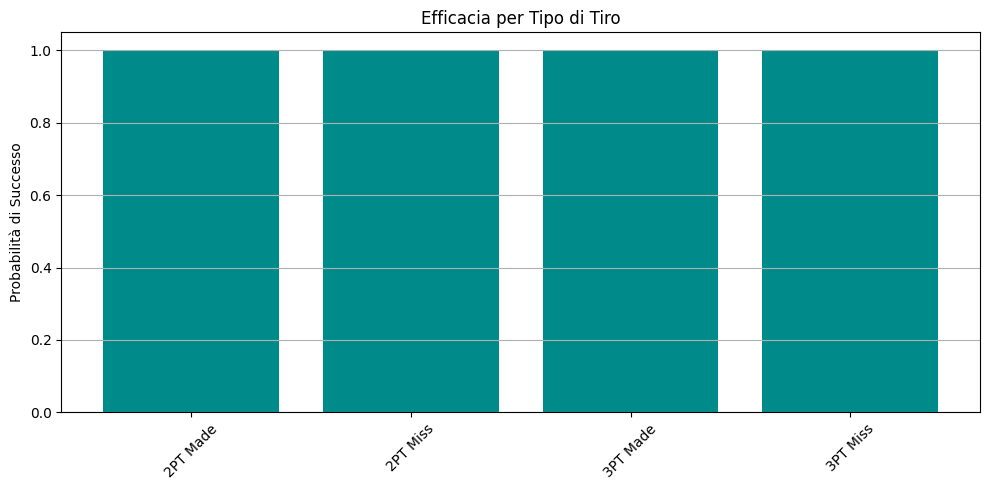

In [97]:
codici_tiro = {
    1: "2PT Made",
    2: "2PT Miss",
    3: "3PT Made",
    4: "3PT Miss",
    13: "FT Made",
    14: "FT Miss"
}

efficacia['descrizione'] = efficacia.index.map(codici_tiro)
efficacia = efficacia.sort_values('probabilità_successo', ascending=False)

# Plot
plt.figure(figsize=(10,5))
plt.bar(efficacia['descrizione'], efficacia['probabilità_successo'], color='darkcyan')
plt.ylabel("Probabilità di Successo")
plt.title("Efficacia per Tipo di Tiro")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


In [98]:
print(df['eventmsgactiontype'].value_counts())


eventmsgactiontype
1     134177
5      33946
79     28399
42     25399
7      11129
       ...  
54        54
53        45
89        41
94        25
95        24
Name: count, Length: 72, dtype: int64


In [99]:
print("eventmsgtype:\n", df['eventmsgtype'].value_counts())
print("eventmsgactiontype:\n", df['eventmsgactiontype'].value_counts())


eventmsgtype:
 eventmsgtype
1    395614
Name: count, dtype: int64
eventmsgactiontype:
 eventmsgactiontype
1     134177
5      33946
79     28399
42     25399
7      11129
       ...  
54        54
53        45
89        41
94        25
95        24
Name: count, Length: 72, dtype: int64


In [100]:
print(pbp['eventmsgactiontype'].value_counts())

eventmsgactiontype
1      2534988
5       582568
79      203977
42      169609
6       155474
        ...   
94         232
110        173
95         143
62         110
91           7
Name: count, Length: 78, dtype: int64


In [101]:
# Filtrare per tiri da 2 punti (ad esempio, codici 1 e 2)
tiri_2p = pbp[pbp['eventmsgactiontype'].isin([1, 2])]
prob_tiro_2p = tiri_2p['success'].mean()
print(f"Probabilità di successo per i tiri da 2 punti: {prob_tiro_2p}")

# Filtrare per tiri da 3 punti (ad esempio, codici 3 e 4)
tiri_3p = pbp[pbp['eventmsgactiontype'].isin([3, 4])]
prob_tiro_3p = tiri_3p['success'].mean()
print(f"Probabilità di successo per i tiri da 3 punti: {prob_tiro_3p}")

# Filtrare per tiri liberi (ad esempio, codice 5)
tiri_libero = pbp[pbp['eventmsgactiontype'] == 5]
prob_tiro_libero = tiri_libero['success'].mean()
print(f"Probabilità di successo per i tiri liberi: {prob_tiro_libero}")

Probabilità di successo per i tiri da 2 punti: 0.35028773942205604
Probabilità di successo per i tiri da 3 punti: 0.48603453893776477
Probabilità di successo per i tiri liberi: 0.468407121572074


In [102]:
# Valore atteso dei tiri
val_atteso_2p = prob_tiro_2p * 2
val_atteso_3p = prob_tiro_3p * 3
val_atteso_libero = prob_tiro_libero * 1

# Riepilogo
print(f"Valore atteso tiro da 2: {val_atteso_2p:.3f}")
print(f"Valore atteso tiro da 3: {val_atteso_3p:.3f}")
print(f"Valore atteso tiro libero: {val_atteso_libero:.3f}")

Valore atteso tiro da 2: 0.701
Valore atteso tiro da 3: 1.458
Valore atteso tiro libero: 0.468


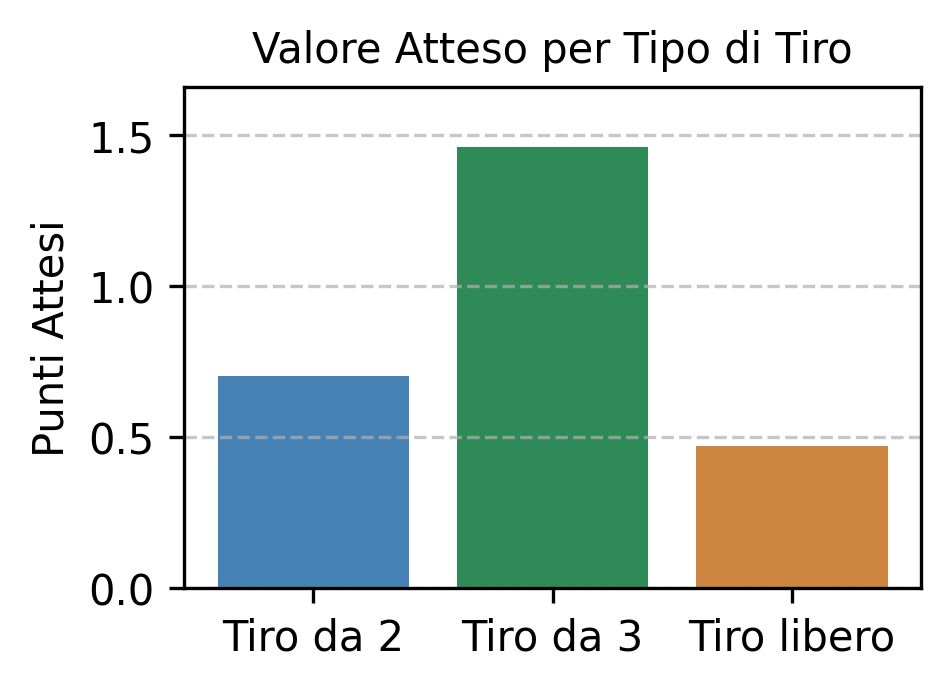

In [103]:
labels = ['Tiro da 2', 'Tiro da 3', 'Tiro libero']
valori = [val_atteso_2p, val_atteso_3p, val_atteso_libero]


plt.figure(figsize=(3.27, 2.4), dpi=300)
plt.bar(labels, valori, color=['steelblue', 'seagreen', 'peru'])
plt.title("Valore Atteso per Tipo di Tiro", fontsize=10)
plt.ylabel("Punti Attesi", fontsize=10)
plt.ylim(0, max(valori) + 0.2)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [137]:
# Prima estraiamo l'anno/season dalla game_id
pbp["year_suffix"] = pbp["game_id"].str[3:5].astype(int)
pbp["season"] = np.where(pbp["year_suffix"] < 50,
                         2000 + pbp["year_suffix"],
                         1900 + pbp["year_suffix"])

In [138]:
# Funzione per calcolare valore atteso per stagione
def valore_atteso_per_stagione(df, action_codes, punti):
    grouped = df[df["eventmsgactiontype"].isin(action_codes)].groupby("season")
    success_rate = grouped["success"].mean()
    return success_rate * punti

In [139]:
# Calcoliamo per ciascun tipo di tiro
val2 = valore_atteso_per_stagione(pbp, [1, 2], 2)
val3 = valore_atteso_per_stagione(pbp, [3, 4], 3)
val_ft = valore_atteso_per_stagione(pbp, [5], 1)

In [140]:
# Costruiamo il DataFrame per il plot
val_attesi_df = pd.DataFrame({
    "Tiro da 2": val2,
    "Tiro da 3": val3,
    "Tiro libero": val_ft
}).reset_index()

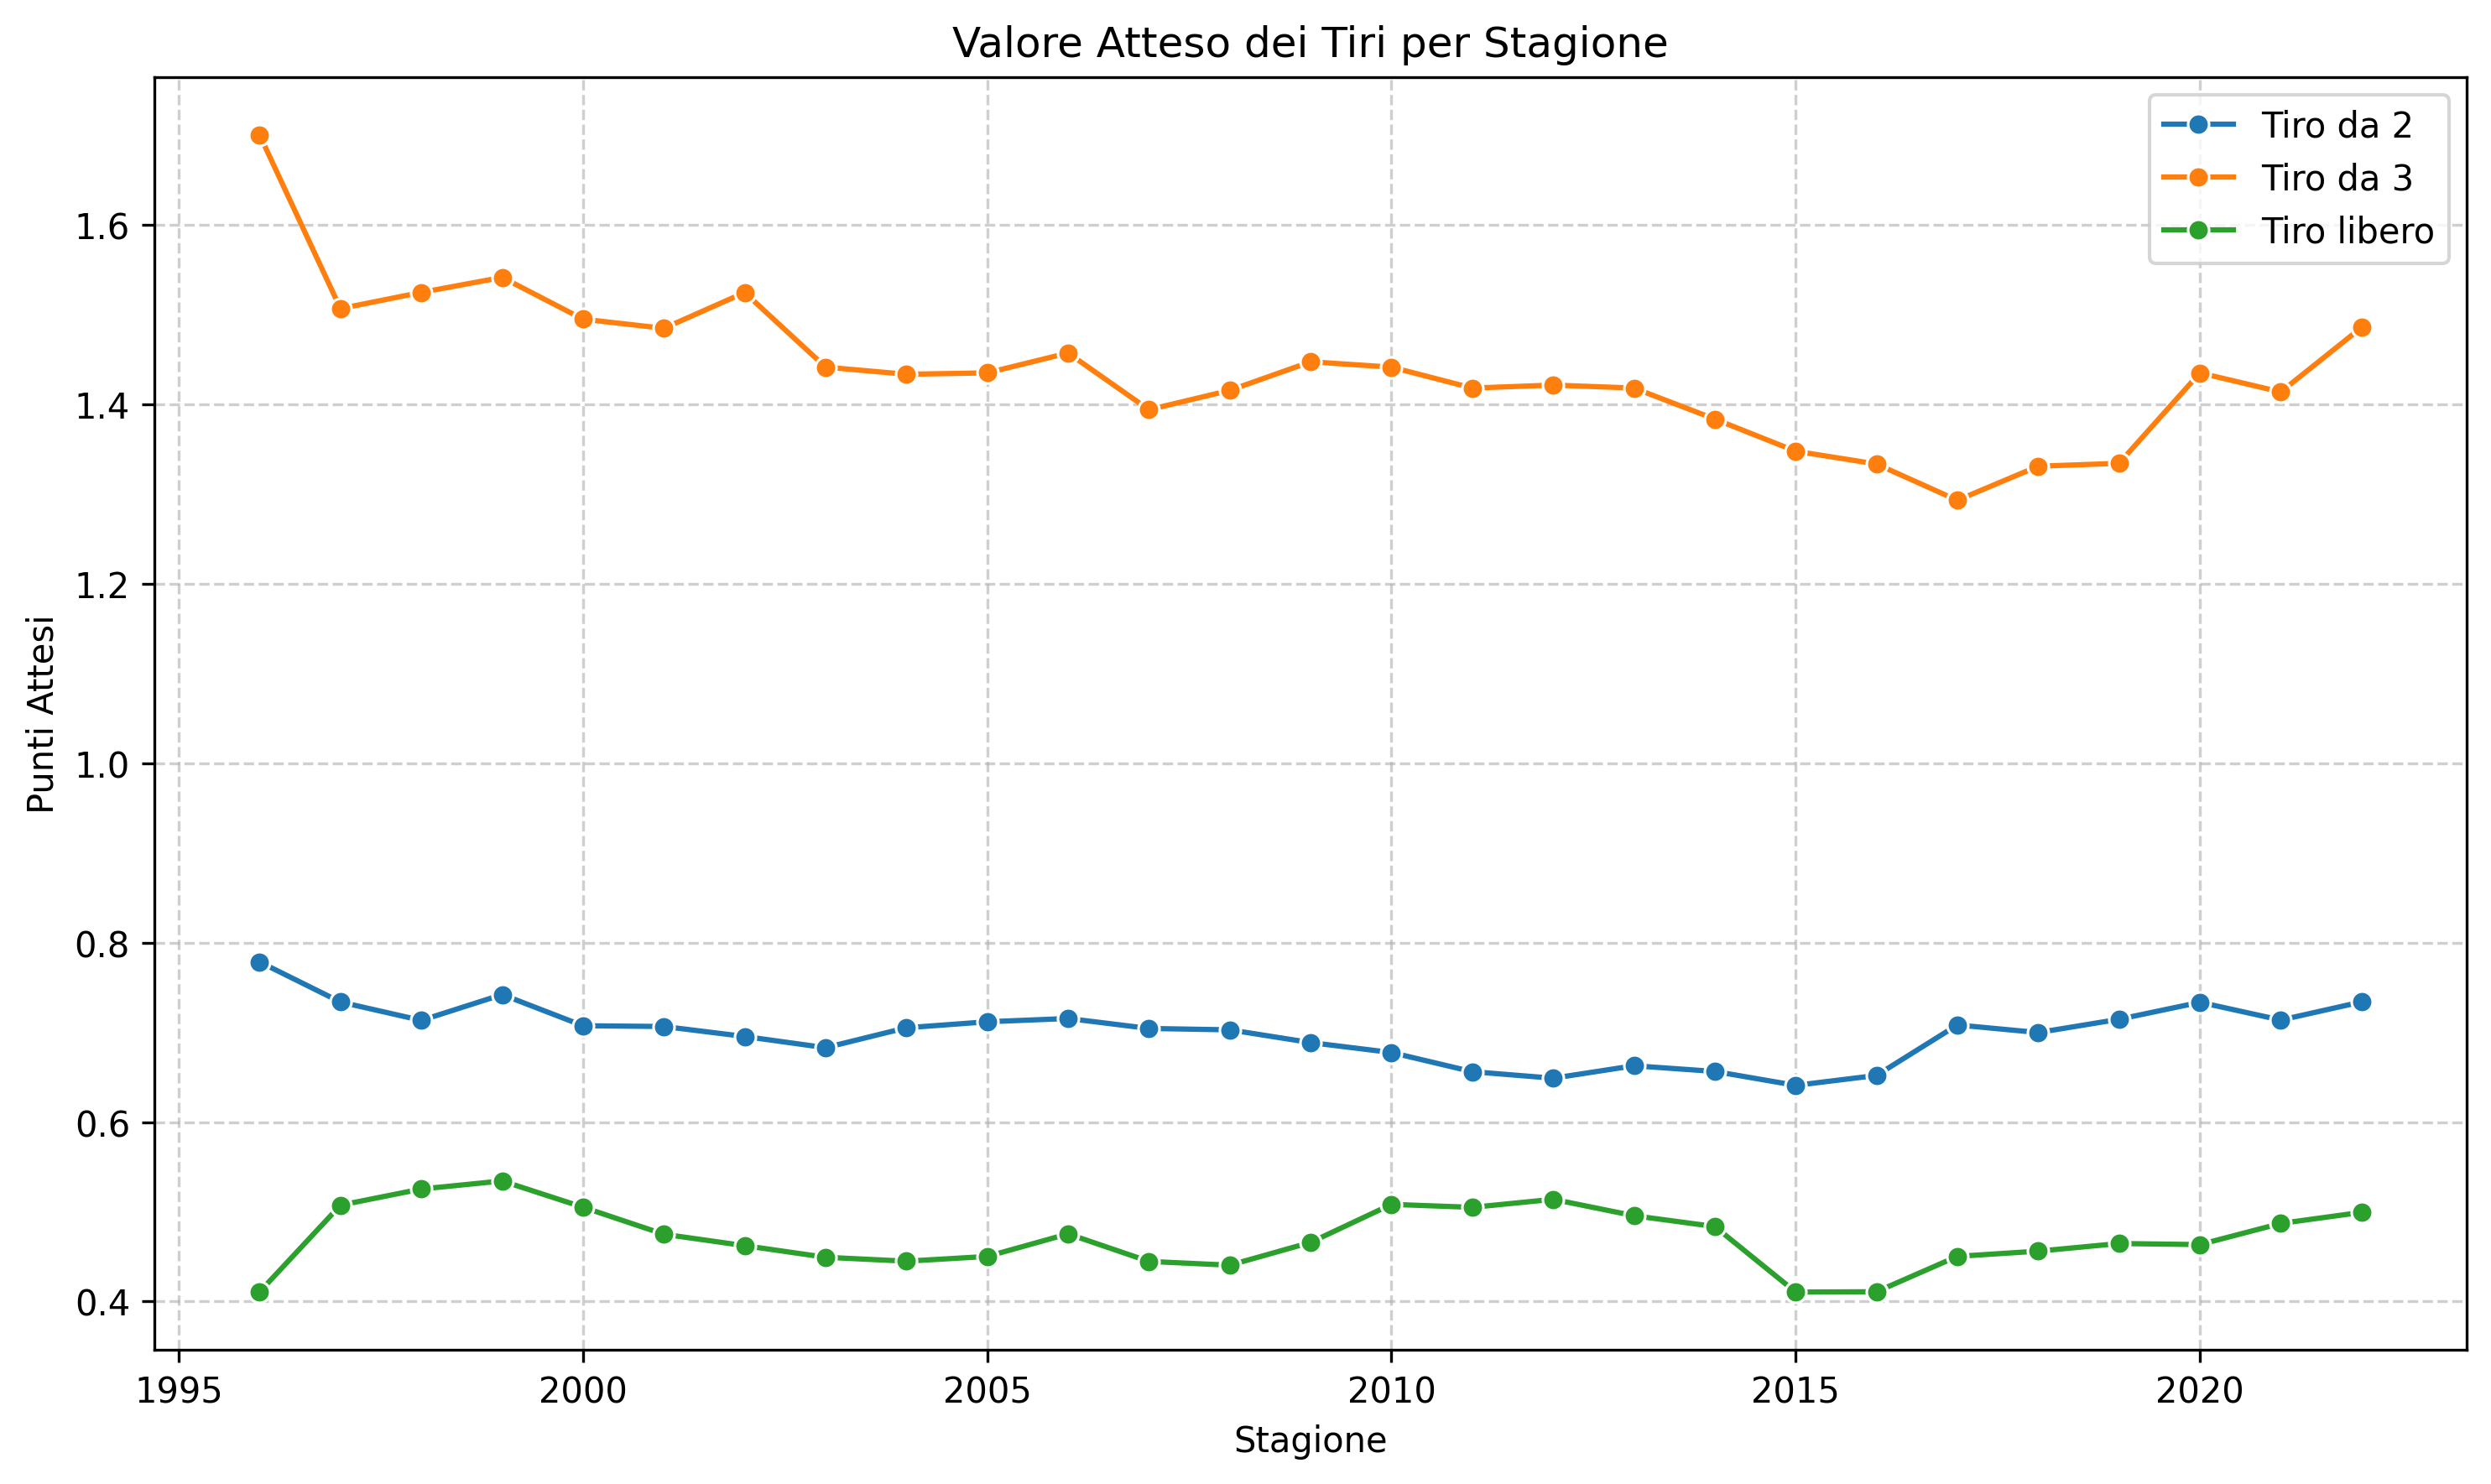

In [141]:
# Plot
import seaborn as sns
plt.figure(figsize=(10, 6), dpi=300)
sns.lineplot(data=val_attesi_df, x="season", y="Tiro da 2", label="Tiro da 2", marker='o')
sns.lineplot(data=val_attesi_df, x="season", y="Tiro da 3", label="Tiro da 3", marker='o')
sns.lineplot(data=val_attesi_df, x="season", y="Tiro libero", label="Tiro libero", marker='o')
plt.title("Valore Atteso dei Tiri per Stagione")
plt.ylabel("Punti Attesi")
plt.xlabel("Stagione")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [109]:
# Filtro solo stagioni 2014–2018
pbp_periodi = pbp[pbp["season"].between(2014, 2018)]

In [110]:
# Funzione per calcolare valore atteso per periodo
def valore_atteso_per_periodo(df, action_codes, punti):
    grouped = df[df["eventmsgactiontype"].isin(action_codes)].groupby("period")
    success_rate = grouped["success"].mean()
    return success_rate * punti

In [111]:
# Calcolo per ogni tipo di tiro
val2 = valore_atteso_per_periodo(pbp_periodi, [1, 2], 2)
val3 = valore_atteso_per_periodo(pbp_periodi, [3, 4], 3)
val_ft = valore_atteso_per_periodo(pbp_periodi, [5], 1)

In [112]:
# Combino i risultati in un DataFrame
val_attesi_periodi = pd.DataFrame({
    "Tiro da 2": val2,
    "Tiro da 3": val3,
    "Tiro libero": val_ft
}).reset_index().sort_values("period")

In [149]:
# Mappa leggibile dei periodi
period_labels = {
    1: "Q1",
    2: "Q2",
    3: "Q3",
    4: "Q4",
    5: "OT1",
    6: "OT2",
    7: "OT3",
    8: "OT4"
}

# Applichiamo la mappa
val_attesi_periodi["period_label"] = val_attesi_periodi["period"].map(period_labels)

# === Grafico principale senza legenda ===
fig, ax = plt.subplots(figsize=(3.27, 2.4), dpi=300)

line1 = sns.lineplot(data=val_attesi_periodi, x="period_label", y="Tiro da 2", label="Tiro da 2", marker='o', ax=ax)
line2 = sns.lineplot(data=val_attesi_periodi, x="period_label", y="Tiro da 3", label="Tiro da 3", marker='o', ax=ax)
line3 = sns.lineplot(data=val_attesi_periodi, x="period_label", y="Tiro libero", label="Tiro libero", marker='o', ax=ax)

ax.set_title("Valore Atteso dei Tiri per Periodo di Gioco", fontsize=10)
ax.set_xlabel("Periodo", fontsize=10)
ax.set_ylabel("Punti Attesi", fontsize=10)

# Salviamo gli handles e rimuoviamo la legenda
handles, labels = ax.get_legend_handles_labels()
ax.legend_.remove()  # Rimuove la legenda se già generata
ax.yaxis.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
fig.savefig("grafico_senza_legenda.png", dpi=300, bbox_inches='tight')
plt.close(fig)

In [114]:
# === Creiamo una figura separata solo per la legenda ===
legend_fig = plt.figure(figsize=(3.27, 2.4), dpi=300)
legend_ax = legend_fig.add_subplot(111)
legend_ax.axis('off')

legend = legend_ax.legend(handles, labels, loc='center', fontsize=10)
legend_fig.savefig("legenda_solo.png", dpi=300, bbox_inches='tight', transparent=True)
plt.close(legend_fig)

In [115]:
prob_success_per_periodo = pbp.groupby('period')['success'].mean()
print(prob_success_per_periodo)

period
1    0.463859
2    0.456454
3    0.453757
4    0.440996
5    0.411702
6    0.400103
7    0.407465
8    0.429907
Name: success, dtype: float64


In [116]:
prob_success_per_squadra = pbp.groupby('player1_team_abbreviation')['success'].mean()
print(prob_success_per_squadra)

player1_team_abbreviation
ADL    0.458564
ALB    0.456790
ATL    0.451184
BAU    0.398810
BKN    0.459510
         ...   
UBB    0.421687
UTA    0.464555
VAN    0.442378
WAS    0.454919
WST    0.517278
Name: success, Length: 62, dtype: float64


In [117]:
# Seleziona solo le righe con tiri
df_tiri = pbp[pbp['eventmsgactiontype'].notna() & (pbp['success'].isin([0,1]))]

In [118]:
# Crea una regressione logistica con formula: success ~ tipo_di_tiro
model = smf.logit('success ~ C(eventmsgactiontype)', data=df_tiri).fit()

Optimization terminated successfully.
         Current function value: 0.640232
         Iterations 8


In [119]:
# Visualizza il riassunto
print(model.summary())

                           Logit Regression Results                           
Dep. Variable:                success   No. Observations:              4941733
Model:                          Logit   Df Residuals:                  4941655
Method:                           MLE   Df Model:                           77
Date:                Mon, 05 May 2025   Pseudo R-squ.:                 0.07060
Time:                        15:20:20   Log-Likelihood:            -3.1639e+06
converged:                       True   LL-Null:                   -3.4042e+06
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                        0.1163      0.114      1.022      0.307      -0.107       0.339
C(eventmsgactiontype)[T.1]      -0.7422      0.114     -6.523      0.000     

In [120]:
odds_list = []
for code in pbp_analisi_clean["eventmsgactiontype"].unique():
    subset = pbp_analisi_clean[pbp_analisi_clean["eventmsgactiontype"] == code]
    successi = subset["success"].sum()
    fallimenti = len(subset) - successi
    if fallimenti == 0 or successi == 0:
        continue
    odds = successi / fallimenti
    odds_list.append({"action_type": code, "odds": odds})

odds_df = pd.DataFrame(odds_list)

In [121]:
# Odds ratio rispetto alla media globale
successi_tot = pbp_analisi_clean["success"].sum()
fallimenti_tot = len(pbp_analisi_clean) - successi_tot
odds_global = successi_tot / fallimenti_tot

odds_df["odds_ratio"] = odds_df["odds"] / odds_global

In [122]:
print(odds_df.head(10))
print(odds_df.shape)

   action_type      odds  odds_ratio
0            1  0.494945    0.596597
1           43  1.827103    2.202357
2           86  0.897665    1.082029
3           49  8.535211   10.288190
4           42  1.697681    2.046354
5           77  0.701225    0.845244
6            5  0.796481    0.960063
7           46  0.777325    0.936974
8           80  0.865792    1.043610
9           52  8.354227   10.070035
(71, 3)


C:\Users\franc\AppData\Local\Temp\ipykernel_13760\1304236930.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=odds_df, x='action_type', y='odds_ratio', palette='viridis')


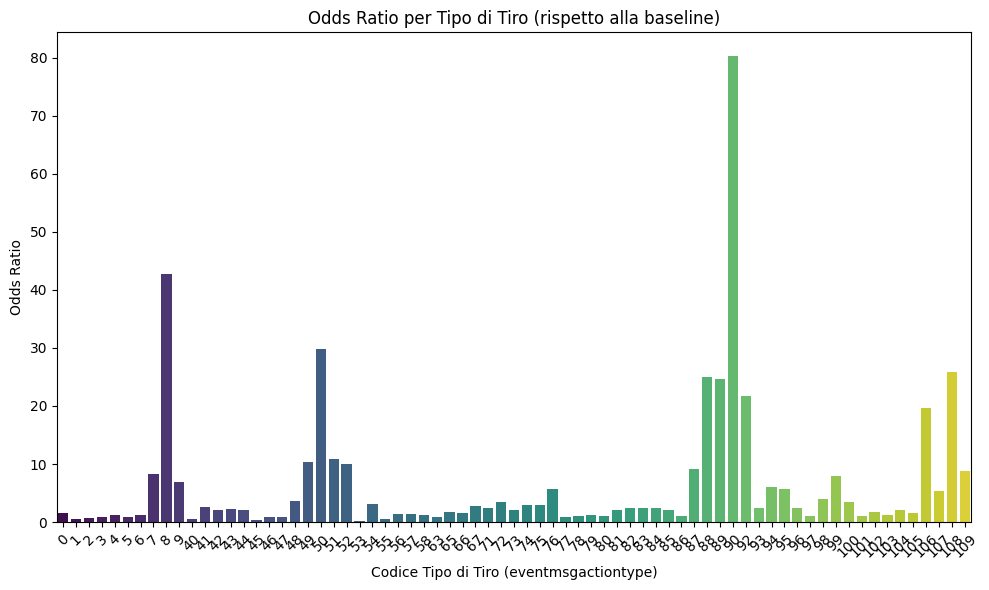

In [123]:
# Ordina e plottiamo
odds_df = odds_df.sort_values("odds_ratio", ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(data=odds_df, x='action_type', y='odds_ratio', palette='viridis')
plt.title("Odds Ratio per Tipo di Tiro (rispetto alla baseline)")
plt.xlabel("Codice Tipo di Tiro (eventmsgactiontype)")
plt.ylabel("Odds Ratio")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [124]:
# Rimuoviamo righe incomplete
df_model = pbp_analisi[['success', 'eventmsgactiontype', 'period']].dropna()

In [125]:
# Rinominiamo per chiarezza
df_model = df_model.rename(columns={
    'eventmsgactiontype': 'action_type',
    'period': 'period'
})

In [126]:
# Convertiamo in categoriche
df_model['action_type'] = df_model['action_type'].astype('category')
df_model['period'] = df_model['period'].astype('category')

In [127]:
# Costruiamo il modello
model = smf.logit('success ~ C(action_type) + C(period)', data=df_model).fit()

         Current function value: 0.635334
         Iterations: 35


C:\Users\franc\anaconda3\envs\myenv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [128]:
# Riassunto dei risultati
print(model.summary())

                           Logit Regression Results                           
Dep. Variable:                success   No. Observations:               872480
Model:                          Logit   Df Residuals:                   872401
Method:                           MLE   Df Model:                           78
Date:                Mon, 05 May 2025   Pseudo R-squ.:                 0.07763
Time:                        17:01:48   Log-Likelihood:            -5.5432e+05
converged:                      False   LL-Null:                   -6.0097e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.3026      0.122      2.489      0.013       0.064       0.541
C(action_type)[T.1]      -0.9801      0.122     -8.060      0.000      -1.218      -0.742
C(action

In [129]:
odds_ratios = np.exp(model.params)
print("\nOdds ratio:\n", odds_ratios)


Odds ratio:
 Intercept              1.353440
C(action_type)[T.1]    0.375273
C(action_type)[T.2]    0.489304
C(action_type)[T.3]    0.594117
C(action_type)[T.4]    0.723191
                         ...   
C(period)[T.4]         0.940860
C(period)[T.5]         0.829181
C(period)[T.6]         0.910873
C(period)[T.7]         0.593970
C(period)[T.8]         1.161338
Length: 79, dtype: float64


In [130]:
model = smf.logit('success ~ C(action_type) + C(period)', data=df_model).fit()

         Current function value: 0.635334
         Iterations: 35


C:\Users\franc\anaconda3\envs\myenv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [131]:
# Coefficienti
params = model.params
conf = model.conf_int()
conf.columns = ['conf_low', 'conf_high']

In [132]:
# Calcolo odds ratio e intervalli
odds = np.exp(params)
conf_exp = np.exp(conf)

C:\Users\franc\anaconda3\envs\myenv\Lib\site-packages\pandas\core\internals\blocks.py:393: RuntimeWarning: overflow encountered in exp
  result = func(self.values, **kwargs)


In [133]:
# Creiamo un DataFrame per il plot
odds_df = pd.DataFrame({
    'feature': odds.index,
    'odds_ratio': odds.values,
    'conf_low': conf_exp['conf_low'],
    'conf_high': conf_exp['conf_high']
})

In [134]:
# Rimuoviamo l'intercetta per il plot (non è interpretabile come effetto relativo)
odds_df = odds_df[odds_df['feature'] != 'Intercept']

C:\Users\franc\AppData\Local\Temp\ipykernel_13760\3330717510.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=odds_df, x='odds_ratio', y='feature', orient='h', palette='viridis', edgecolor='black')


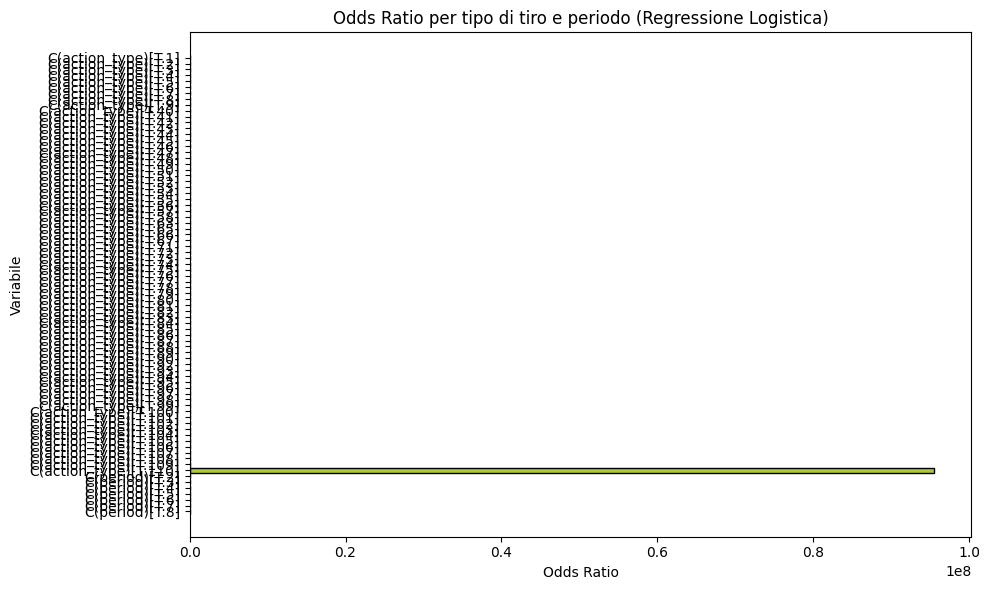

In [135]:
plt.figure(figsize=(10, 6))
sns.barplot(data=odds_df, x='odds_ratio', y='feature', orient='h', palette='viridis', edgecolor='black')

# Aggiungiamo intervalli di confidenza
for i, row in odds_df.iterrows():
    plt.plot([row['conf_low'], row['conf_high']], [i, i], color='black', linewidth=1.5)

plt.axvline(x=1, color='red', linestyle='--')  # Odds ratio = 1 come riferimento
plt.xlabel("Odds Ratio")
plt.ylabel("Variabile")
plt.title("Odds Ratio per tipo di tiro e periodo (Regressione Logistica)")
plt.tight_layout()
plt.show()